# Same pay gap, same shape?
### BA305 Team A6 · descriptive question · Levent's notebook

**Data:** the team file `UK_Gender_Pay_Gap_workbook_allyears.csv` (UK gender pay gap filings, TidyTuesday 2022-06-28), reporting period 2021–2022. Same file, sample rules and measure names as Josh's notebook, so the two can be read side by side.

## The question

> Among UK employers that report a **similar median hourly pay gap**, do they all look alike in where women sit across the four pay quartiles, or do they differ: women mainly **missing from the highest-paid quartile** in some, and mainly **crowded into the lowest-paid quartile** in others?

**Why this wording.** It asks how employers spread out and what the main ways they differ are, which is what charts and PCA can answer. It does not ask what *causes* a gap: the filings show where women sit, not why.

**Who would act on the answer.** Our client is a workplace gender-equality certification body. If every employer with a 10% gap looked the same inside, the body could send each of them the same request. If they differ, the request should depend on the employer: evidence on **who gets the top jobs** (promotion, senior hiring) or on **who fills the lowest-paid jobs** (entry-level hiring, moving up from there).

**Results that would surprise us**
1. **A similar gap always going with a similar quartile pattern.** Then the headline number would be all a reviewer needs.
2. **Employers falling into two clearly separate camps.** Then a simple "top" or "bottom" label would do.
3. **The bottom of the pay ladder mattering as much as the top.** The usual story about pay gaps is the "glass ceiling", too few women at the top.

**Short answer (details in section 7).** Employers with a similar gap do not look alike. Most have both too few women at the top and too many at the bottom, but the balance between the two varies widely, along one continuous range. That balance is stable from year to year, unrelated to the size of the gap, and related to the gender mix of the workforce. PCA finds the same pattern without being told to look for it.

## How the notebook is organised

| Section | What it does |
|---|---|
| 1 to 3 | Data, who is in the sample, the measures, pipeline diagram |
| 4 | **Method 1: structured charts** (eight steps, each with one job) |
| 5 | **Method 2: PCA** on the four quartile shares |
| 6 and 7 | Do the two methods agree? The answer, and what the client would do differently |
| 8 and 9 | Assumptions and limitations; what we tried that did not work |

Every step follows the same order: **why** we do it, the **code**, then **what the output shows**. Numbers quoted in the notes were read from the outputs of a full run on 16 November 2026. If the team file changes, re-read them from the outputs.

**AI disclosure (project directives §9).** The code in this notebook was written with the help of Claude (Anthropic; models Claude Fable 5.2 and Claude Opus 5.5) in November 2026, and every AI-assisted code cell says so in its first lines. The explanatory notes were drafted with the same tool as study notes. They are **not** report or slide text: the report and slides are written in our own words.

## 1. Data

**What the file is.** Since 2017, UK employers with 250 or more staff must publish gender pay gap figures every year ([UK government guidance](https://www.gov.uk/government/publications/gender-pay-gap-reporting-guidance-for-employers/when-to-report)). Each row of the team file is one employer's filing for one reporting period.

**How the quartiles work.** The employer ranks all its employees by hourly pay and splits them into four groups of equal size, from the lowest-paid quartile to the highest-paid quartile. It then reports the percentage of women in each group.

**Columns this analysis uses**

| Column | Type | Role here |
|---|---|---|
| `FemaleLowerQuartile`, `FemaleLowerMiddleQuartile`, `FemaleUpperMiddleQuartile`, `FemaleTopQuartile` | numeric, 0 to 100 (%) | **The inputs.** Women's share of each pay quartile |
| `DiffMedianHourlyPercent` | numeric (%) | Used only to **group** employers with a similar gap. Positive means men's median hourly pay is higher |
| `ReportingPeriod` | categorical | Picks the year |
| `EmployerSize` | categorical, ordered | Sample rule, and a third variable |
| `Industry` | categorical, unordered | A third variable |
| `EmployerId`, `CurrentName` | labels | Check for repeats, match an employer across years, name the examples |

**Columns left out, and why**
- **Male quartile columns:** each is 100 minus the female one, so they add nothing.
- **Mean gap and bonus columns:** they belong to a different question (Nick's notebook covers them).
- **Address, postcode, company number, links, responsible person:** labels for a filing, not information about pay.

**There is no output variable.** Nothing is predicted in this notebook, so there is no train/test split and no leakage to check. The PCA in section 5 describes the 2021–2022 employers; it is not used as an input to any model.

In [1]:
# --- Levent: setup and data loading ---
# AI-assisted (Claude Fable 5.2, Anthropic, November 2026). See the AI note at the top.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.max_columns", 50)

# One colour per idea, used the same way in every chart
BLUE = "#2a78d6"      # the TOP of the pay ladder (top deficit)
ORANGE = "#eb6834"    # the BOTTOM of the pay ladder (bottom excess)
GRAY = "#52514e"      # neutral marks and reference lines
LIGHT_GRAY = "#c3c2b7"

def save_figure(name):
    # Saves the current chart as a PNG file (in Colab: the Files panel on the left)
    plt.savefig(name + ".png", dpi=200, bbox_inches="tight")

# The team's data file, read straight from the team repository (same file Josh uses)
DATA_URL = ("https://raw.githubusercontent.com/runkael2/"
            "BA305-A6-Team-Project/main/UK_Gender_Pay_Gap_workbook_allyears.csv")
all_filings = pd.read_csv(DATA_URL, encoding="utf-8-sig", low_memory=False)

# The team file calls the employer's name "CurrentName". Rename the heading only.
all_filings = all_filings.rename(columns={"CurrentName": "EmployerName"})

print("Rows and columns in the team file:", all_filings.shape)
print()
print("Filings in each reporting period:")
print(all_filings["ReportingPeriod"].value_counts().sort_index())

Rows and columns in the team file: (48711, 31)

Filings in each reporting period:
ReportingPeriod
2017-2018    10230
2018-2019    10471
2019-2020     6924
2020-2021    10536
2021-2022    10425
2022-2023      125
Name: count, dtype: int64


**What the output shows.** The file holds 48,711 filings across six reporting periods. 2022–2023 has only 125 because the file was downloaded before most employers had filed, so the latest complete period is 2021–2022.

## 2. Who is in the analysis

Three rules, each with a reason:

1. **One reporting period, 2021–2022.** Most employers file every year, so using all years would count the same employer up to six times. One period means one row per employer. 2021–2022 is the latest complete period and the one the rest of the team uses.
2. **Employers with 250 or more staff.** The law only requires these to report. Smaller employers are not required to, so the ones in the file are a self-selected group, and with few people in each quartile their shares jump around. Filings with no size given are left out for the same reason. This rule defines the population; it is not a missing-data fix. Section 4.8 checks that it does not change the answer.
3. **All four quartile shares filled in, and between 0 and 100.** The directives ask us to fill in missing values when more than about 5% are missing. Here the share is well under that, and the quartile shares are the very thing we study, so inventing them would be wrong. We drop these rows and report how many.

In [2]:
# --- Levent: sample selection (who is in the analysis) ---
# AI-assisted (Claude Fable 5.2, November 2026)
PERIOD = "2021-2022"
gap_col = "DiffMedianHourlyPercent"
female_cols = ["FemaleLowerQuartile", "FemaleLowerMiddleQuartile",
               "FemaleUpperMiddleQuartile", "FemaleTopQuartile"]
size_order = ["250 to 499", "500 to 999", "1000 to 4999",
              "5000 to 19,999", "20,000 or more"]

# Step 1: one reporting period, so that every employer appears once
step1 = all_filings[all_filings["ReportingPeriod"] == PERIOD].copy()

# Step 2: employers with 250 or more staff (the ones the law requires to report)
step2 = step1[step1["EmployerSize"].isin(size_order)].copy()

# Step 3: all four quartile shares are filled in and lie between 0 and 100
has_all_four = step2[female_cols].notna().all(axis=1)
in_range = step2[female_cols].ge(0).all(axis=1) & step2[female_cols].le(100).all(axis=1)
df = step2[has_all_four & in_range].copy()

audit = pd.DataFrame(
    {"Employers left": [len(step1), len(step2), len(df)],
     "Removed at this step": [len(all_filings) - len(step1),
                              len(step1) - len(step2),
                              len(step2) - len(df)]},
    index=["1. Reporting period 2021-2022",
           "2. 250 or more staff",
           "3. Usable quartile data"])
display(audit)

missing_pct = 100 * (len(step2) - len(df)) / len(step2)
print(f"Step 3 removes {missing_pct:.1f}% of the step-2 employers,")
print("all of them because the quartile boxes are blank.")
print("Employers that appear more than once:", df["EmployerId"].duplicated().sum())
print("Employers with no median gap reported:", df[gap_col].isna().sum())

,Employers left,Removed at this step
1. Reporting period 2021-2022,10425,38286
2. 250 or more staff,9661,764
3. Usable quartile data,9494,167


Step 3 removes 1.7% of the step-2 employers,
all of them because the quartile boxes are blank.
Employers that appear more than once: 0
Employers with no median gap reported: 0


**What the output shows**
- **10,425 employers filed for 2021–2022,** each exactly once.
- **Rule 2 removes 764 (7.3%). Rule 3 removes 167 (1.7%),** all because the quartile boxes were left blank.
- **9,494 employers remain.** None is missing its median gap.

**Two things worth flagging before going on.** They stay in the sample, because the rules above are meant to be simple and these rows cannot move a median. Section 4.8 tests what happens without them.

In [3]:
# --- Levent: data-quality flags (kept in the sample, re-tested in section 4.8) ---
# AI-assisted (Claude Fable 5.2, November 2026)

# Flag 1: the exact same share typed into all four quartiles (looks like a placeholder)
same_in_all_four = df[female_cols].nunique(axis=1) == 1
# Flag 2: a median gap beyond -100% or +100%
extreme_gap = df[gap_col].abs() > 100

print("Same share in all four quartiles:", same_in_all_four.sum(), "employers")
print("Median gap beyond -100% or +100%:", extreme_gap.sum(), "employers")
display(df.loc[same_in_all_four | extreme_gap, ["EmployerName", gap_col] + female_cols].head(8))

Same share in all four quartiles: 18 employers
Median gap beyond -100% or +100%: 3 employers


,EmployerName,DiffMedianHourlyPercent,FemaleLowerQuartile,FemaleLowerMiddleQuartile,FemaleUpperMiddleQuartile,FemaleTopQuartile
38612,ANGEL HUMAN RESOURCES LIMITED,50.0,50.0,50.0,50.0,50.0
39593,BRYAN'S SALADS LTD.,0.0,35.0,35.0,35.0,35.0
39855,CARTREFI CYMRU CO-OPERATIVE LIMITED,0.0,77.0,77.0,77.0,77.0
40070,CHOICE HOTELS LIMITED,0.0,100.0,100.0,100.0,100.0
40143,City of London Police,0.0,24.0,24.0,24.0,24.0
41595,FORTEL SERVICES LIMITED,-128.8,6.6,1.0,3.9,0.5
41695,FULL HOUSE RESTAURANTS HOLDINGS LIMITED,9.3,25.0,25.0,25.0,25.0
41741,G4S SECURE SOLUTIONS (UK) LIMITED,-275.9,15.7,11.5,12.3,11.3


**What the output shows**
- **18 employers typed the same share into all four quartiles** (for example 50 / 50 / 50 / 50). A real workforce of 250 or more people almost never splits that evenly, so these look like placeholders. One of them falls in our 8–12% group.
- **3 employers report a median gap below −100%.** That is possible in principle (it means women's median pay is more than double men's) but unusual. All three sit in the "0 or below" group in section 4.4.

## 3. The measures

**The idea.** Each quartile holds a quarter of the employer's staff. If women were spread evenly across pay levels, every quartile would have the same share of women as the employer overall. So we compare each end of the pay ladder with the employer's overall share.

| Measure | Formula | Plain meaning |
|---|---|---|
| Overall share | average of the four quartile shares | women's share of the whole workforce |
| **Top deficit** | overall share − share in the highest-paid quartile | how many points **fewer** women at the top than overall |
| **Bottom excess** | share in the lowest-paid quartile − overall share | how many points **more** women at the bottom than overall |
| **Contrast** | top deficit − bottom excess | above 0: the top side is larger. Below 0: the bottom side is larger |

**A made-up example.** An employer is 50% women overall. Its highest-paid quartile is 35% women, so the top deficit is 15. Its lowest-paid quartile is 55% women, so the bottom excess is 5. The contrast is 15 − 5 = +10: this employer's imbalance sits mostly at the top.

**Assumptions built into these measures**
- **Overall share is the average of the four quartiles.** This is exact when the four groups are the same size, which is how the quartiles are defined.
- **The unit is percentage points, which here means people.** A top deficit of 15 says that out of every 100 people in the highest-paid quartile, 15 fewer are women than an even spread would give.
- **The two measures are linked by arithmetic.** Both are measured from the same overall share, and the four quartiles' differences from that share always add up to zero. Because of this, the contrast also equals the average of the two middle quartiles minus the average of the two end quartiles.
- **Negative values are allowed.** A negative top deficit means women are over-represented at the top.
- **They describe where women sit, not why.** They also say nothing about pay differences inside a quartile.
- **Values are rounded to 4 decimal places.** Computers store decimals with tiny errors, so a contrast of exactly zero can come out as 0.00000000000001 and be counted as "top side larger". The filings have one decimal place, so rounding to 4 changes no real value and keeps exact ties as ties. The code below shows how many employers this affects.

**Why compare employers with a similar gap.** Employers with bigger gaps have more of both top deficit and bottom excess (section 4.4 shows this). To see *where* a gap sits, we have to hold its *size* roughly fixed. The main group is employers with a median gap of **8% to 12%**. It is centred on the typical employer (the median gap in the sample is 9.85%) and it is the group Josh uses. The width is a judgement call, tested in section 4.8.

In [4]:
# --- Levent: the measures (same formulas and names as Josh's notebook) ---
# AI-assisted (Claude Fable 5.2, November 2026)

# Why .round(4) everywhere below: computers store decimals with tiny errors, so a
# difference that is exactly 0 can come out as 0.00000000000001 and be counted as
# "above zero". The filings have one decimal place, so rounding to 4 keeps every
# value exact and removes those errors.

# Women's share of the whole workforce = average of the four quartile shares
# (axis=1 means "across the columns of each row", so one number per employer)
df["OverallFemaleShareApprox"] = df[female_cols].mean(axis=1).round(4)

# Top deficit: how many points FEWER women the highest-paid quartile has than the employer overall
df["TopDeficit_pp"] = (df["OverallFemaleShareApprox"] - df["FemaleTopQuartile"]).round(4)

# Bottom excess: how many points MORE women the lowest-paid quartile has than the employer overall
df["BottomExcess_pp"] = (df["FemaleLowerQuartile"] - df["OverallFemaleShareApprox"]).round(4)

# Contrast: positive = top deficit is the larger side, negative = bottom excess is the larger side
df["Contrast_pp"] = (df["TopDeficit_pp"] - df["BottomExcess_pp"]).round(4)

# A label for each employer (Josh's rule: a side must lead by more than 2 points to count)
def pattern_label(top, bottom, tolerance=2):
    lead = round(top - bottom, 4)      # how far the top side leads (negative: the bottom leads)
    if top <= 0 and bottom <= 0:
        return "Neither positive"
    if top > 0 and lead > tolerance:
        return "Top deficit larger"
    if bottom > 0 and -lead > tolerance:
        return "Bottom excess larger"
    return "Similar/unclear"

pattern_order = ["Top deficit larger", "Bottom excess larger",
                 "Similar/unclear", "Neither positive"]
labels = []
for top, bottom in zip(df["TopDeficit_pp"], df["BottomExcess_pp"]):
    labels.append(pattern_label(top, bottom))
df["Pattern"] = labels

# Groups of employers by the size of their median gap (used in section 4.4)
gap_edges = [-1000, 0, 5, 10, 15, 20, 30, 1000]
gap_names = ["0 or below", "0-5%", "5-10%", "10-15%", "15-20%", "20-30%", "above 30%"]
df["GapBand"] = pd.cut(df[gap_col], bins=gap_edges, labels=gap_names)

# The main comparison group: employers with a SIMILAR gap, 8% to 12%
GAP_LOW, GAP_HIGH = 8, 12
band = df[df[gap_col].between(GAP_LOW, GAP_HIGH)].copy()

print("Employers in the full sample:", len(df))
print("Median of the median gaps in the full sample:", round(df[gap_col].median(), 2), "%")
print("Employers with a gap of 8% to 12%:", len(band), "(Josh's notebook: 982)")
measure_cols = ["OverallFemaleShareApprox", "TopDeficit_pp", "BottomExcess_pp", "Contrast_pp"]
display(band[measure_cols].describe().round(2))

# Does the rounding matter? Count the employers whose two sides are exactly equal,
# with the rounding and without it.
average = band[female_cols].mean(axis=1)
unrounded = (average - band["FemaleTopQuartile"]) - (band["FemaleLowerQuartile"] - average)
print("Employers in the 8-12% group whose two sides are exactly equal:")
print("   with the rounding:   ", (band["Contrast_pp"] == 0).sum())
print("   without the rounding:", (unrounded == 0).sum())

Employers in the full sample: 9494
Median of the median gaps in the full sample: 9.85 %
Employers with a gap of 8% to 12%: 982 (Josh's notebook: 982)


,OverallFemaleShareApprox,TopDeficit_pp,BottomExcess_pp,Contrast_pp
count,982.00,982.00,982.00,982.00
mean,45.15,7.22,7.13,0.09
std,22.39,5.96,6.97,8.35
min,3.98,-25.00,-29.48,-35.65
25%,24.50,3.52,3.00,-4.75
50%,46.18,7.25,7.05,0.00
75%,62.50,10.75,11.00,5.50
max,96.42,31.75,38.25,33.70


Employers in the 8-12% group whose two sides are exactly equal:
   with the rounding:    20
   without the rounding: 17


**What the output shows.** 982 employers have a gap of 8–12%, the same count as Josh's notebook. In this group:
- **The typical employer has both.** The median top deficit is 7.25 points and the median bottom excess is 7.05 points.
- **The contrast is centred on zero but spreads widely.** Half of the employers lie between −4.75 and +5.5.
- **Gender mix varies a lot,** from 4% to 96% women, with a median of 46%.
- **The rounding matters a little.** 20 employers have two exactly equal sides. Without the rounding only 17 would be counted as ties, and the other 3 would be counted as "top side larger".

### Pipeline diagram
The flow from the raw file to the answer. The counts in the boxes are computed, not typed in.

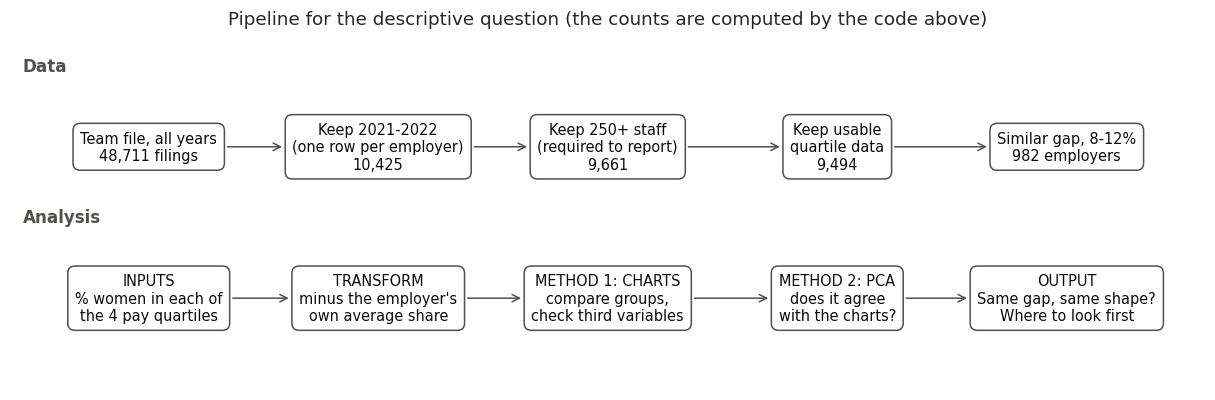

In [5]:
# --- Levent: pipeline diagram (raw file -> sample -> measures -> two methods -> answer) ---
# AI-assisted (Claude Fable 5.2, November 2026)
data_row = [
    "Team file, all years\n" + f"{len(all_filings):,} filings",
    "Keep 2021-2022\n(one row per employer)\n" + f"{len(step1):,}",
    "Keep 250+ staff\n(required to report)\n" + f"{len(step2):,}",
    "Keep usable\nquartile data\n" + f"{len(df):,}",
    "Similar gap, 8-12%\n" + f"{len(band):,} employers",
]
analysis_row = [
    "INPUTS\n% women in each of\nthe 4 pay quartiles",
    "TRANSFORM\nminus the employer's\nown average share",
    "METHOD 1: CHARTS\ncompare groups,\ncheck third variables",
    "METHOD 2: PCA\ndoes it agree\nwith the charts?",
    "OUTPUT\nSame gap, same shape?\nWhere to look first",
]
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.set_xlim(-0.6, 4.6)
ax.set_ylim(-0.6, 1.75)
ax.axis("off")
for row_number, row in enumerate([data_row, analysis_row]):
    y = 1 - row_number
    boxes = []
    for i, text in enumerate(row):
        box = ax.text(i, y, text, ha="center", va="center", fontsize=9.5, color="#0b0b0b",
                      bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor=GRAY))
        boxes.append(box)
    # an arrow from the right edge of each box to the left edge of the next one
    for i in range(len(boxes) - 1):
        ax.annotate("", xy=(0, 0.5), xycoords=boxes[i + 1].get_bbox_patch(),
                    xytext=(1, 0.5), textcoords=boxes[i].get_bbox_patch(),
                    arrowprops=dict(arrowstyle="->", color=GRAY))
ax.text(-0.55, 1.5, "Data", fontsize=11, fontweight="bold", color=GRAY)
ax.text(-0.55, 0.5, "Analysis", fontsize=11, fontweight="bold", color=GRAY)
ax.set_title("Pipeline for the descriptive question (the counts are computed by the code above)")
save_figure("fig00_pipeline")
plt.show()

## 4. Method 1: structured charts

**Why charts first.** The question is about how employers spread out, and a chart of every employer shows that directly. Each chart below has one job:

| Step | Chart | Its job |
|---|---|---|
| 4.1 | Two real employers | Make the question concrete |
| 4.2 | One dot per employer | Do similar-gap employers look alike? |
| 4.3 | Histogram of the contrast | Two camps, or one continuous range? |
| 4.4 | Boxplots by gap size | Is the 8–12% group special? |
| 4.5 | Gender mix | Third variable |
| 4.6 | Size and industry | Third variables |
| 4.7 | Same employers a year earlier | Real feature, or noise? |
| 4.8 | Table of re-runs | Do our own choices drive the answer? |

**Colour means the same thing throughout:** blue for the top of the pay ladder, orange for the bottom.

### 4.1 Two real employers with a similar gap

**Why.** To see what "same gap, different shape" looks like before looking at 982 employers at once.

**How the two were chosen.** We want the two shapes in their cleanest form, so that only one end of the pay ladder stands out:
1. **Shortlist by a fixed rule.** *Top shape:* the three lower quartiles are within 3 points of each other, and the highest-paid quartile is at least 10 points below all of them. *Bottom shape:* the three upper quartiles are within 3 points of each other, and the lowest-paid quartile is at least 10 points above all of them.
2. **Pick one pair from the shortlists** that is as alike as possible on everything else: gap, size and share of women.

**This is an illustration, not evidence, and the pair is deliberately clean.** Only a few dozen of the 982 employers have a pure shape like these. Most have some of both, as section 4.2 shows. Both shortlists are printed so anyone can pick a different pair.

Employers with the top shape:    30 of 982
Employers with the bottom shape: 22 of 982


,EmployerName,Industry,EmployerSize,DiffMedianHourlyPercent,OverallFemaleShareApprox,FemaleLowerQuartile,FemaleLowerMiddleQuartile,FemaleUpperMiddleQuartile,FemaleTopQuartile
41084,ELISABETH THE CHEF LIMITED,Manufacturing,250 to 499,8.9,41.2,48.2,45.6,48.2,23.0
41937,GOODWOOD ROAD RACING COMPANY LIMITED,Arts/Entertainment,250 to 499,10.6,59.6,64.7,64.7,65.0,44.0
38930,AXA PPP HEALTHCARE GROUP LIMITED,Finance/Insurance,1000 to 4999,11.9,60.8,65.5,66.8,66.0,45.0
45455,RCI FINANCIAL SERVICES LIMITED,Finance/Insurance,250 to 499,10.6,53.8,58.0,60.0,58.0,39.0
47825,University Hospital Southampton NHS Foundation...,Health/SocialWork,"5000 to 19,999",11.5,75.0,78.5,78.9,80.5,62.0
40952,East and North Hertfordshire NHS Trust,Health/SocialWork,"5000 to 19,999",9.2,76.3,80.0,80.6,81.0,63.7
47279,THE OFFICE CONCIERGE COMPANY LIMITED,AdministrativeServices,250 to 499,9.9,85.3,89.8,89.9,88.5,73.0
46488,ST CUTHBERT'S ROMAN CATHOLIC ACADEMY TRUST,Education,500 to 999,9.7,77.4,81.7,80.8,81.7,65.4
39932,CENTER PARCS LIMITED,Finance/Insurance,"5000 to 19,999",9.7,51.6,56.1,54.3,56.7,39.2
48295,Weymouth College,Education,250 to 499,8.5,63.8,68.8,67.6,67.0,51.9


,EmployerName,Industry,EmployerSize,DiffMedianHourlyPercent,OverallFemaleShareApprox,FemaleLowerQuartile,FemaleLowerMiddleQuartile,FemaleUpperMiddleQuartile,FemaleTopQuartile
39438,BRC LIMITED,Manufacturing,250 to 499,11.7,12.8,32.6,6.1,6.1,6.3
45076,PHILIPS ELECTRONICS UK LIMITED,Manufacturing,1000 to 4999,10.2,36.4,54.2,31.1,30.7,29.6
38188,A H WORTH LIMITED,Manufacturing,250 to 499,10.7,41.2,59.0,37.0,35.0,34.0
40840,DORMAKABA UK LIMITED,Manufacturing,250 to 499,9.8,25.6,40.8,21.2,19.2,21.2
48135,WARNER BROS. STUDIOS LEAVESDEN LIMITED,Communications/Information,250 to 499,10.9,55.2,69.5,50.0,50.0,51.2
38195,A. SHARE & SONS LIMITED,Wholesale & Retail Trade,1000 to 4999,11.0,29.5,44.0,26.0,24.0,24.0
38535,ALTRAN UK LIMITED,Scientific/Technical,500 to 999,9.2,20.4,35.1,15.3,14.1,17.1
46074,SHAKESPEARE GLOBE TRUST(THE),Arts/Entertainment,250 to 499,11.0,65.2,79.0,62.0,59.0,61.0
41067,ELAVON FINANCIAL SERVICES DAC,Unknown,250 to 499,8.0,37.6,50.0,33.8,34.2,32.4
38553,AMAZON DEVELOPMENT CENTRE (LONDON) LIMITED,AdministrativeServices,1000 to 4999,11.1,20.0,32.2,16.7,16.0,15.2


Both examples are on their shortlist: True


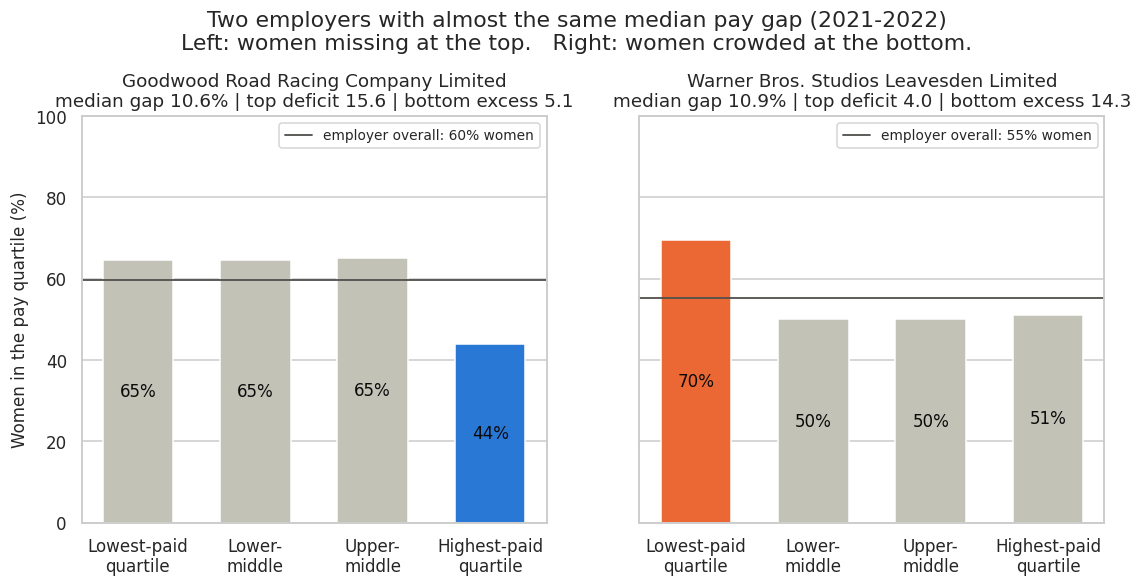

In [6]:
# --- Levent: 4.1 two real employers with a similar gap (an illustration, not evidence) ---
# AI-assisted (Claude Opus 5.5, Anthropic, November 2026)

# Step 1: a shortlist of employers whose profile is "level, except at one end".
#   Top shape:    the three lower quartiles lie within 3 points of each other,
#                 and the highest-paid quartile is at least 10 points below all of them.
#   Bottom shape: the three upper quartiles lie within 3 points of each other,
#                 and the lowest-paid quartile is at least 10 points above all of them.
LEVEL = 3
STEP = 10
lower_three = band[female_cols[:3]]     # lowest-paid, lower-middle, upper-middle
upper_three = band[female_cols[1:]]     # lower-middle, upper-middle, highest-paid

lower_three_spread = (lower_three.max(axis=1) - lower_three.min(axis=1)).round(4)
upper_three_spread = (upper_three.max(axis=1) - upper_three.min(axis=1)).round(4)
band["StepAtTop"] = (lower_three.min(axis=1) - band["FemaleTopQuartile"]).round(4)
band["StepAtBottom"] = (band["FemaleLowerQuartile"] - upper_three.max(axis=1)).round(4)

top_shape = (lower_three_spread <= LEVEL) & (band["StepAtTop"] >= STEP)
bottom_shape = (upper_three_spread <= LEVEL) & (band["StepAtBottom"] >= STEP)

print("Employers with the top shape:   ", top_shape.sum(), "of", len(band))
print("Employers with the bottom shape:", bottom_shape.sum(), "of", len(band))
show_cols = ["EmployerName", "Industry", "EmployerSize", gap_col,
             "OverallFemaleShareApprox"] + female_cols
display(band.loc[top_shape].sort_values("StepAtTop", ascending=False)[show_cols].round(1))
display(band.loc[bottom_shape].sort_values("StepAtBottom", ascending=False)[show_cols].round(1))

# Step 2: from the shortlists, one pair that is as alike as possible on everything except
# the shape: almost the same gap (10.6% and 10.9%), the same size band (250-499 staff),
# a similar share of women (60% and 55%), and both entertainment businesses
# (motor-racing events and a film studio), although the file puts them in different industries.
example_top = band[band["EmployerName"] == "GOODWOOD ROAD RACING COMPANY LIMITED"].iloc[0]
example_bottom = band[band["EmployerName"] == "WARNER BROS. STUDIOS LEAVESDEN LIMITED"].iloc[0]
print("Both examples are on their shortlist:",
      bool(top_shape[example_top.name]) and bool(bottom_shape[example_bottom.name]))

# Step 3: the chart. Only the end that differs is coloured.
quartile_ticks = ["Lowest-paid\nquartile", "Lower-\nmiddle",
                  "Upper-\nmiddle", "Highest-paid\nquartile"]
bar_colors = {"top": [LIGHT_GRAY, LIGHT_GRAY, LIGHT_GRAY, BLUE],
              "bottom": [ORANGE, LIGHT_GRAY, LIGHT_GRAY, LIGHT_GRAY]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
panels = [(axes[0], example_top, "top"), (axes[1], example_bottom, "bottom")]
for ax, example, shape_name in panels:
    shares = example[female_cols].tolist()
    overall = example["OverallFemaleShareApprox"]
    ax.bar(quartile_ticks, shares, color=bar_colors[shape_name], width=0.6)
    ax.axhline(overall, color=GRAY, linewidth=1.2,
               label=f"employer overall: {overall:.0f}% women")
    for i, value in enumerate(shares):
        ax.text(i, value / 2, f"{value:.0f}%", ha="center", va="center",
                fontsize=11, color="#0b0b0b")
    title_line_1 = example["EmployerName"].title()
    title_line_2 = (f"median gap {example[gap_col]:.1f}% | "
                    f"top deficit {example['TopDeficit_pp']:.1f} | "
                    f"bottom excess {example['BottomExcess_pp']:.1f}")
    ax.set_title(title_line_1 + "\n" + title_line_2)
    ax.set_ylim(0, 100)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper right", fontsize=9)
axes[0].set_ylabel("Women in the pay quartile (%)")
fig.suptitle("Two employers with almost the same median pay gap (2021-2022)\n"
             "Left: women missing at the top.   Right: women crowded at the bottom.", y=1.08)
save_figure("fig01_two_employers")
plt.show()

**What the output shows**
- **The shortlists:** 30 employers have the top shape and 22 the bottom shape.
- **Goodwood Road Racing Company** (gap 10.6%, 250–499 staff, about 60% women): women are 65% of each of the three lower quartiles, then 44% of the highest-paid one.
- **Warner Bros. Studios Leavesden** (gap 10.9%, 250–499 staff, about 55% women): women are 50–51% of each of the three upper quartiles, then 70% of the lowest-paid one.
- **Almost the same headline gap, and mirror-image profiles.** The imbalance sits entirely at one end in each. Both are entertainment businesses (motor-racing events and a film studio), though the file lists them under different industries.
- **Why Goodwood still shows a bottom excess of 5.1, though its lowest quartile is level with the middle ones.** The low top quartile pulls the employer's overall share down to 60%, so the three level quartiles all sit about 5 points above that line. Whenever only one end differs, the other side's measure comes out at about a third of the main one (15.6 against 5.1 for Goodwood; 14.3 against 4.0 for Warner Bros.). The contrast still points clearly to the right end.

### 4.2 Every employer, one dot each

**Why.** Averages hide spread. Here each of the 982 employers is one dot: its top deficit from left to right, its bottom excess from bottom to top. On the diagonal line the two are equal. Below the line the top deficit is larger; above it the bottom excess is larger. The colours use Josh's rule: a side must lead by more than 2 points to count as larger.

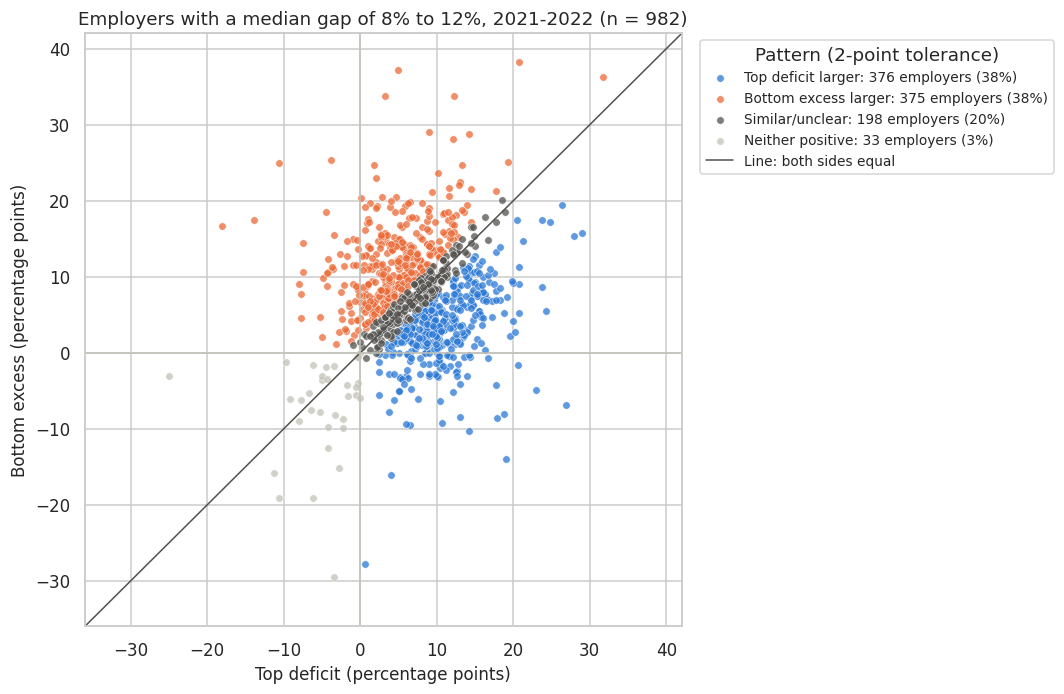

,Employers
Pattern,
Top deficit larger,376
Bottom excess larger,375
Similar/unclear,198
Neither positive,33


Both top deficit and bottom excess are positive for 82.9 % of these employers


In [7]:
# --- Levent: 4.2 every employer with an 8-12% gap, one dot each ---
# AI-assisted (Claude Fable 5.2, November 2026)
pattern_colors = {"Top deficit larger": BLUE, "Bottom excess larger": ORANGE,
                  "Similar/unclear": GRAY, "Neither positive": LIGHT_GRAY}

fig, ax = plt.subplots(figsize=(7, 7))
for name in pattern_order:
    group = band[band["Pattern"] == name]
    share = 100 * len(group) / len(band)
    ax.scatter(group["TopDeficit_pp"], group["BottomExcess_pp"], s=24, alpha=0.75,
               color=pattern_colors[name], edgecolor="white", linewidth=0.4,
               label=f"{name}: {len(group)} employers ({share:.0f}%)")
ax.plot([-36, 42], [-36, 42], color=GRAY, linewidth=1, label="Line: both sides equal")
ax.axhline(0, color=LIGHT_GRAY, linewidth=1)
ax.axvline(0, color=LIGHT_GRAY, linewidth=1)
ax.set_xlim(-36, 42)
ax.set_ylim(-36, 42)
ax.set_xlabel("Top deficit (percentage points)")
ax.set_ylabel("Bottom excess (percentage points)")
ax.set_title(f"Employers with a median gap of 8% to 12%, 2021-2022 (n = {len(band)})")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9,
          title="Pattern (2-point tolerance)")
save_figure("fig02_scatter_top_vs_bottom")
plt.show()

display(band["Pattern"].value_counts().reindex(pattern_order).to_frame("Employers"))
both_positive = (band["TopDeficit_pp"] > 0) & (band["BottomExcess_pp"] > 0)
print("Both top deficit and bottom excess are positive for",
      round(100 * both_positive.mean(), 1), "% of these employers")

**What the output shows**
- **Most employers have both.** For 83% of them both measures are positive (the upper-right quarter of the chart).
- **But the balance differs a lot from one employer to the next.** The top deficit is the larger side for 376 employers (38%), the bottom excess for 375 (38%), 198 (20%) are too close to call, and for 33 (3%) neither is positive. These match Josh's counts exactly.
- **Where to look:** the cloud straddles the diagonal, with about as many dots on each side.

### 4.3 Two camps, or one continuous range?

**Why.** The 38% / 38% split could mean two separate kinds of employer, or one continuous range that happens to straddle zero. A histogram of the contrast tells them apart: two camps would show up as two humps.

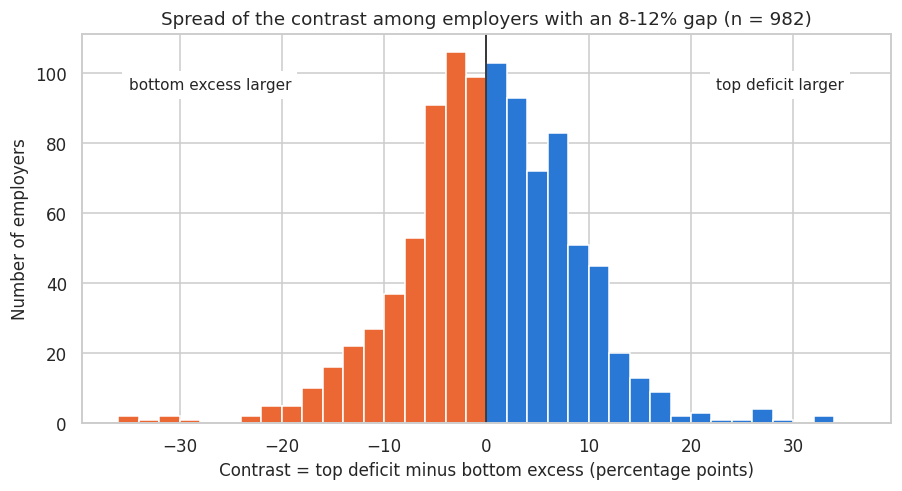

Contrast, middle half of employers: -4.8 to 5.5
Contrast, middle 80% of employers: -10.0 to 10.0


In [8]:
# --- Levent: 4.3 one hump or two? The spread of the contrast ---
# AI-assisted (Claude Fable 5.2, November 2026)
fig, ax = plt.subplots(figsize=(9.5, 4.6))
counts, edges, bars = ax.hist(band["Contrast_pp"], bins=np.arange(-36, 37, 2), edgecolor="white")
for bar, left_edge in zip(bars, edges[:-1]):
    if left_edge < 0:
        bar.set_facecolor(ORANGE)     # bottom excess is the larger side
    else:
        bar.set_facecolor(BLUE)       # top deficit is the larger side
ax.axvline(0, color="#0b0b0b", linewidth=1)
top_of_chart = counts.max()
white_box = dict(facecolor="white", edgecolor="none")
ax.text(-35, top_of_chart * 0.9, "bottom excess larger", fontsize=10, ha="left", bbox=white_box)
ax.text(35, top_of_chart * 0.9, "top deficit larger", fontsize=10, ha="right", bbox=white_box)
ax.set_xlabel("Contrast = top deficit minus bottom excess (percentage points)")
ax.set_ylabel("Number of employers")
ax.set_title(f"Spread of the contrast among employers with an 8-12% gap (n = {len(band)})")
save_figure("fig03_contrast_histogram")
plt.show()

# quantile(0.25) is the value that a quarter of employers fall below, and so on
q10 = band["Contrast_pp"].quantile(0.10)
q25 = band["Contrast_pp"].quantile(0.25)
q75 = band["Contrast_pp"].quantile(0.75)
q90 = band["Contrast_pp"].quantile(0.90)
print("Contrast, middle half of employers:", round(q25, 1), "to", round(q75, 1))
print("Contrast, middle 80% of employers:", round(q10, 1), "to", round(q90, 1))

**What the output shows**
- **One hump, centred on zero.** There is no dip in the middle separating a "top" group from a "bottom" group. Employers range smoothly from strongly bottom-heavy to strongly top-heavy.
- **The range is wide.** Half of the employers lie between −4.8 and +5.5, and eight in ten lie between −10 and +10. A contrast of 10 is large: it is the difference between, say, a top deficit of 12 and a bottom excess of 2.

**Would a different, equally reasonable chart tell a different story?** Yes, twice, which is why all three views are shown:
- **Medians alone** (7.25 against 7.05) would suggest employers are all alike, with both sides equal. That hides the spread.
- **The labelled counts alone** (38% against 38%) would suggest two camps. The histogram shows there are none, and section 4.8 shows the counts move with the tolerance we pick.
- **The histogram is the fair summary:** one continuous range, wide, centred on zero.

### 4.4 Is the 8–12% group special?

**Why.** A finding that only holds in one hand-picked group is fragile. Here all 9,494 employers are split into seven groups by the size of their gap, and the two measures are compared within each group.

**Reading the chart.** Each box holds the middle half of employers, the line inside is the median, and the whiskers show the rest of the usual range. Points beyond the whiskers are hidden so the boxes stay readable; they exist in every group.

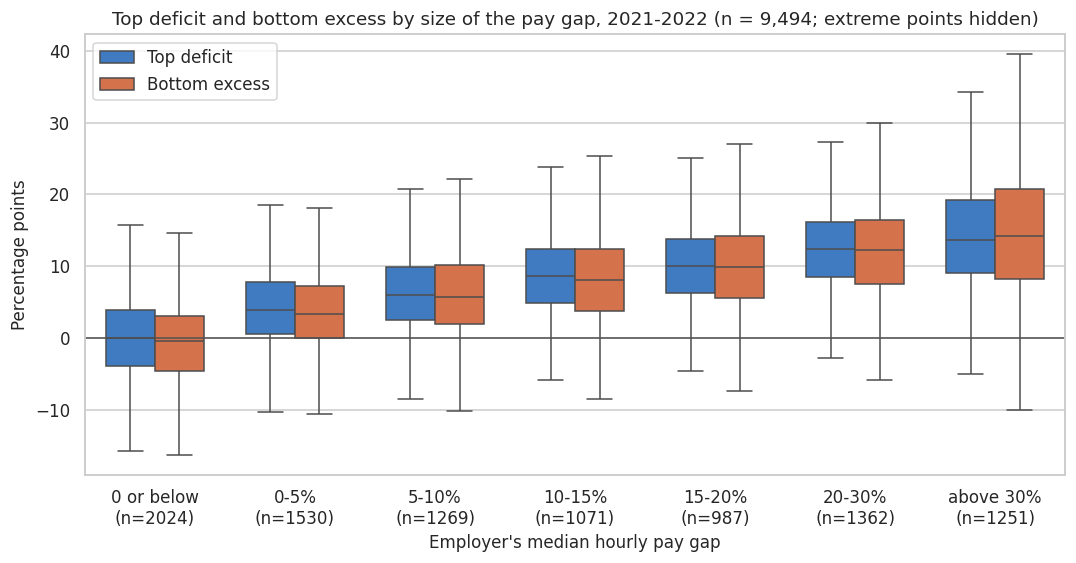

,Median top deficit,Median bottom excess,Median contrast,Top deficit larger,Bottom excess larger,Similar/unclear,Neither positive
GapBand,,,,,,,
0 or below,0.06,-0.40,0.60,30.2,23.6,14.2,32.1
0-5%,3.90,3.38,0.50,37.5,32.8,23.0,6.7
5-10%,6.08,5.78,0.00,38.2,35.9,21.1,4.7
10-15%,8.68,8.10,0.25,41.8,36.1,19.9,2.1
15-20%,10.05,9.98,0.00,37.1,37.5,23.2,2.2
20-30%,12.49,12.26,0.00,38.3,37.5,22.4,1.8
above 30%,13.72,14.25,-0.05,38.0,39.7,20.9,1.4


Correlation with the median gap, all employers:
  top deficit   0.61
  bottom excess 0.61
  contrast      -0.05


In [9]:
# --- Levent: 4.4 compare groups: every gap size, not only 8-12% ---
# AI-assisted (Claude Fable 5.2, November 2026)

# Reshape to "long" form: one row per employer and measure, so seaborn can draw the pairs of boxes
long_table = df.melt(id_vars="GapBand", value_vars=["TopDeficit_pp", "BottomExcess_pp"],
                     var_name="Measure", value_name="Points")
long_table["Measure"] = long_table["Measure"].replace(
    {"TopDeficit_pp": "Top deficit", "BottomExcess_pp": "Bottom excess"})

band_counts = df["GapBand"].value_counts()
tick_labels = []
for name in gap_names:
    tick_labels.append(f"{name}\n(n={band_counts[name]})")

fig, ax = plt.subplots(figsize=(11.5, 5.2))
sns.boxplot(data=long_table, x="GapBand", y="Points", hue="Measure", order=gap_names,
            hue_order=["Top deficit", "Bottom excess"],
            palette={"Top deficit": BLUE, "Bottom excess": ORANGE},
            showfliers=False, width=0.7, linewidth=1, ax=ax)
ax.axhline(0, color=GRAY, linewidth=1)
ax.set_xticks(range(len(gap_names)))
ax.set_xticklabels(tick_labels)
ax.set_xlabel("Employer's median hourly pay gap")
ax.set_ylabel("Percentage points")
ax.set_title("Top deficit and bottom excess by size of the pay gap, 2021-2022 "
             f"(n = {len(df):,}; extreme points hidden)")
ax.legend(title="")
save_figure("fig04_all_gap_bands")
plt.show()

three_measures = ["TopDeficit_pp", "BottomExcess_pp", "Contrast_pp"]
gap_table = df.groupby("GapBand", observed=True)[three_measures].median().round(2)
gap_table.columns = ["Median top deficit", "Median bottom excess", "Median contrast"]
pattern_by_gap = (100 * pd.crosstab(df["GapBand"], df["Pattern"], normalize="index")).round(1)
display(gap_table.join(pattern_by_gap[pattern_order]))
print("Correlation with the median gap, all employers:")
print("  top deficit  ", round(df["TopDeficit_pp"].corr(df[gap_col], method="spearman"), 2))
print("  bottom excess", round(df["BottomExcess_pp"].corr(df[gap_col], method="spearman"), 2))
print("  contrast     ", round(df["Contrast_pp"].corr(df[gap_col], method="spearman"), 2))

**What the output shows**
- **Both measures grow with the gap.** The median top deficit climbs from 3.9 (gap 0–5%) to 13.7 (gap above 30%), and the median bottom excess from 3.4 to 14.3. Each has a rank correlation of 0.61 with the gap.
- **The balance between them does not change.** The median contrast stays between −0.05 and +0.6 in every group, and its rank correlation with the gap is −0.05. In every group with a positive gap, the top deficit is the larger side for 37–42% of employers and the bottom excess for 33–40%.
- **So the gap tells you how much imbalance there is, not where it sits.** The 8–12% group is not special.
- **The "0 or below" group is different, as it should be.** With no gap in men's favour, both measures sit near zero, and for 32% of employers neither is positive.

### 4.5 Third variable: the gender mix of the workforce

**Why.** The measures are built from the employer's overall share of women, so that share is the first thing that could be shaping the result. Employers in the group range from 4% to 96% women. They are split into four groups by that share.

**A warning about the yardstick.** Percentages cannot go below 0 or above 100. An employer with 10% women cannot have a top deficit above 10 points (its highest-paid quartile cannot have fewer than 0% women), while its bottom excess can reach 30 (if all of its women were in the lowest-paid quartile). For an employer with 90% women it is the reverse. So when we measure in points, employers with few women are pushed toward "bottom excess larger" and employers with many women toward "top deficit larger", whatever is really going on.

**A second yardstick without that cap: odds.** Odds are women divided by men. In a quartile that is 20% women, the odds are 20 ÷ 80 = 0.25.
- **Top side** = odds overall ÷ odds in the highest-paid quartile. A value of 2 means the odds of an employee being a woman are half as high at the top as overall.
- **Bottom side** = odds in the lowest-paid quartile ÷ odds overall.

Ratios like these do not run into the 0 and 100 limits. If the pattern were only an effect of the cap, it should disappear on this yardstick.

**Assumption.** A share of exactly 0 or 100 gives odds of 0 or infinity, so shares are kept between 0.5 and 99.5 before dividing. The code prints how many employers this touches.

**Note.** "Which side is larger" uses no tolerance in this step (simply contrast above or below zero), so that the two yardsticks can be compared like for like.

,Employers,Median top deficit,Median bottom excess,Median contrast,"Top side larger, % (points)","Top side larger, % (odds)"
GenderMix,,,,,,
under 25% women,255,3.5,7.2,-3.6,25.9,35.7
25-50% women,285,8.4,8.8,0.0,49.8,55.1
50-75% women,337,9.2,7.5,1.5,57.3,54.6
over 75% women,105,8.2,3.2,4.5,78.1,71.4


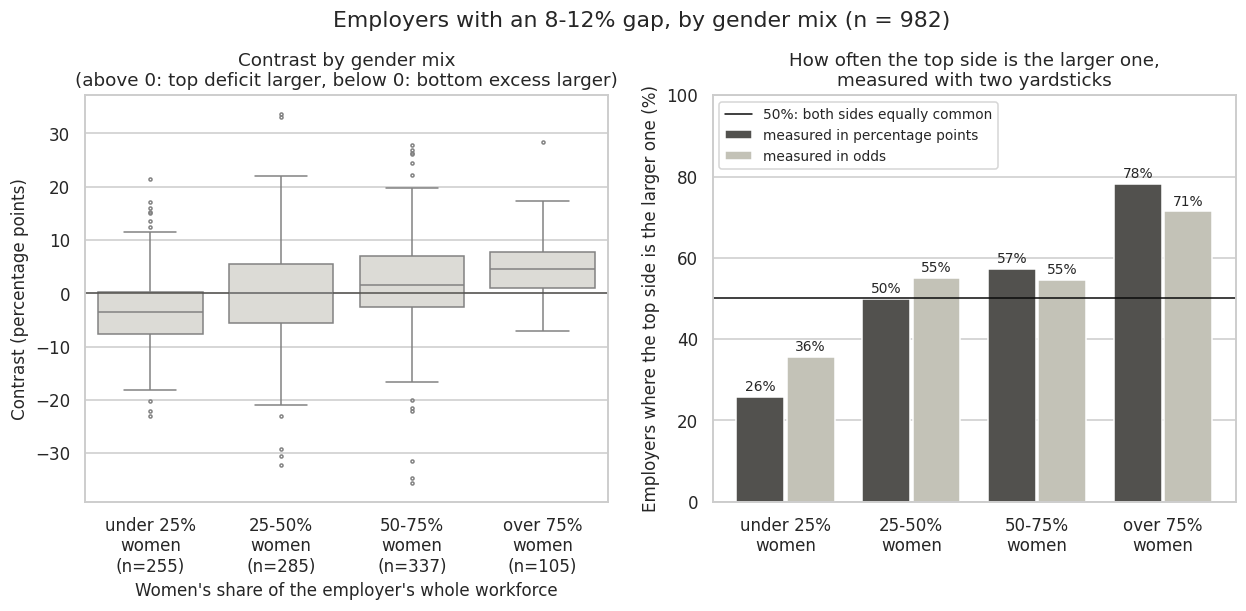

All band employers together, top side larger:
   measured in points: 49.2 %
   measured in odds:   51.6 %
Employers with a quartile share moved to 0.5 or 99.5 for the odds: 3
Rank correlation between contrast and women's overall share (band): 0.36


In [10]:
# --- Levent: 4.5 third variable: the gender mix of the workforce ---
# AI-assisted (Claude Fable 5.2, November 2026)
mix_names = ["under 25% women", "25-50% women", "50-75% women", "over 75% women"]
band["GenderMix"] = pd.cut(band["OverallFemaleShareApprox"],
                           bins=[0, 25, 50, 75, 100], labels=mix_names)

# A second yardstick that has no 0-100 cap: odds (women divided by men).
def odds(share_percent):
    # A share of exactly 0 or 100 would give odds of 0 or infinity,
    # so every share is first kept between 0.5 and 99.5.
    share = share_percent.clip(0.5, 99.5)
    return share / (100 - share)

# Top side: how many times lower the odds of being a woman are in the highest-paid quartile
band["TopSideOdds"] = odds(band["OverallFemaleShareApprox"]) / odds(band["FemaleTopQuartile"])
# Bottom side: how many times higher those odds are in the lowest-paid quartile
band["BottomSideOdds"] = odds(band["FemaleLowerQuartile"]) / odds(band["OverallFemaleShareApprox"])

band["TopLargerPoints"] = band["Contrast_pp"] > 0
band["TopLargerOdds"] = (band["TopSideOdds"] - band["BottomSideOdds"]).round(6) > 0

by_mix = band.groupby("GenderMix", observed=True)
mix_table = pd.DataFrame({
    "Employers": by_mix["Contrast_pp"].size(),
    "Median top deficit": by_mix["TopDeficit_pp"].median(),
    "Median bottom excess": by_mix["BottomExcess_pp"].median(),
    "Median contrast": by_mix["Contrast_pp"].median(),
    "Top side larger, % (points)": 100 * by_mix["TopLargerPoints"].mean(),
    "Top side larger, % (odds)": 100 * by_mix["TopLargerOdds"].mean(),
})
display(mix_table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
sns.boxplot(data=band, x="GenderMix", y="Contrast_pp", order=mix_names, color="#dddcd5",
            fliersize=2, linewidth=1, ax=axes[0])
axes[0].axhline(0, color=GRAY, linewidth=1)
short_names = []      # the group names on two lines, so they fit under the chart
mix_ticks = []        # the same, with the number of employers added
for name in mix_names:
    short = name.replace(" women", "\nwomen")
    count = mix_table.loc[name, "Employers"]
    short_names.append(short)
    mix_ticks.append(short + f"\n(n={count})")
axes[0].set_xticks(range(len(mix_names)))
axes[0].set_xticklabels(mix_ticks)
axes[0].set_xlabel("Women's share of the employer's whole workforce")
axes[0].set_ylabel("Contrast (percentage points)")
axes[0].set_title("Contrast by gender mix\n"
                  "(above 0: top deficit larger, below 0: bottom excess larger)")

positions = np.arange(len(mix_names))
bars_points = axes[1].bar(positions - 0.2, mix_table["Top side larger, % (points)"], width=0.38,
                          color=GRAY, label="measured in percentage points")
bars_odds = axes[1].bar(positions + 0.2, mix_table["Top side larger, % (odds)"], width=0.38,
                        color=LIGHT_GRAY, label="measured in odds")
for bar in list(bars_points) + list(bars_odds):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                 f"{bar.get_height():.0f}%", ha="center", fontsize=9)
axes[1].axhline(50, color="#0b0b0b", linewidth=1, label="50%: both sides equally common")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(short_names)
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Employers where the top side is the larger one (%)")
axes[1].set_title("How often the top side is the larger one,\nmeasured with two yardsticks")
axes[1].legend(loc="upper left", fontsize=9)
axes[1].grid(axis="x", visible=False)
fig.suptitle(f"Employers with an 8-12% gap, by gender mix (n = {len(band)})", y=1.04)
save_figure("fig05_gender_mix")
plt.show()

print("All band employers together, top side larger:")
print("   measured in points:", round(100 * band["TopLargerPoints"].mean(), 1), "%")
print("   measured in odds:  ", round(100 * band["TopLargerOdds"].mean(), 1), "%")
touched = ((band[female_cols] < 0.5) | (band[female_cols] > 99.5)).any(axis=1).sum()
print("Employers with a quartile share moved to 0.5 or 99.5 for the odds:", touched)
print("Rank correlation between contrast and women's overall share (band):",
      round(band["Contrast_pp"].corr(band["OverallFemaleShareApprox"], method="spearman"), 2))

**What the output shows**
- **The balance shifts with the gender mix.** Measured in points, the top deficit is the larger side for 26% of employers with under 25% women, 50% and 57% in the two middle groups, and 78% of employers with over 75% women. The median contrast runs from −3.6 to +4.5.
- **Part of that is the yardstick; most of it is not.** In odds, the same four figures are 36%, 55%, 55% and 71%. The shift shrinks at both ends but keeps its direction.
- **In the two middle groups it is close to even on both yardsticks** (50–57%). These hold 622 of the 982 employers.
- **Both kinds exist in every group.** Among employers with under 25% women, about one in four still has the top side larger. Among those with over 75% women, about one in five does not.
- **What this changes.** The even split in section 4.2 is a blend: employers with mostly male workforces lean toward bottom excess, and employers with mostly female workforces lean toward top deficit.
- **The 0.5 to 99.5 rule touched 3 employers.**

### 4.6 Third variables: employer size and industry

**Why.** A reviewer would ask whether this is simply a matter of big against small employers, or of one industry against another. Industries are ordered from the fewest to the most women, so the link with section 4.5 is visible. Only industries with at least 30 employers in the group are shown, and "Unknown" is left out because it is a missing label, not an industry.

,Employers,Median women's share,Median contrast,"Top side larger, %"
Industry,,,,
Transportation/Storage,38,16.1,-4.6,26.3
Manufacturing,208,23.1,-3.5,28.4
Wholesale & Retail Trade,90,29.6,0.5,50.0
Communications/Information,68,31.6,1.7,61.8
AdministrativeServices,70,46.3,-0.2,45.7
Scientific/Technical,76,49.8,2.0,59.2
PublicDefense/Security,61,59.4,0.6,57.4
Education,99,65.2,-0.4,42.4
Health/SocialWork,83,77.2,4.1,81.9


,Employers,Median women's share,Median contrast,"Top side larger, %"
EmployerSize,,,,
250 to 499,410,44.9,0.0,49.8
500 to 999,239,39.0,-1.9,40.2
1000 to 4999,242,50.0,0.2,50.8
"5000 to 19,999",80,55.9,3.9,67.5
"20,000 or more",11,51.2,0.2,54.5


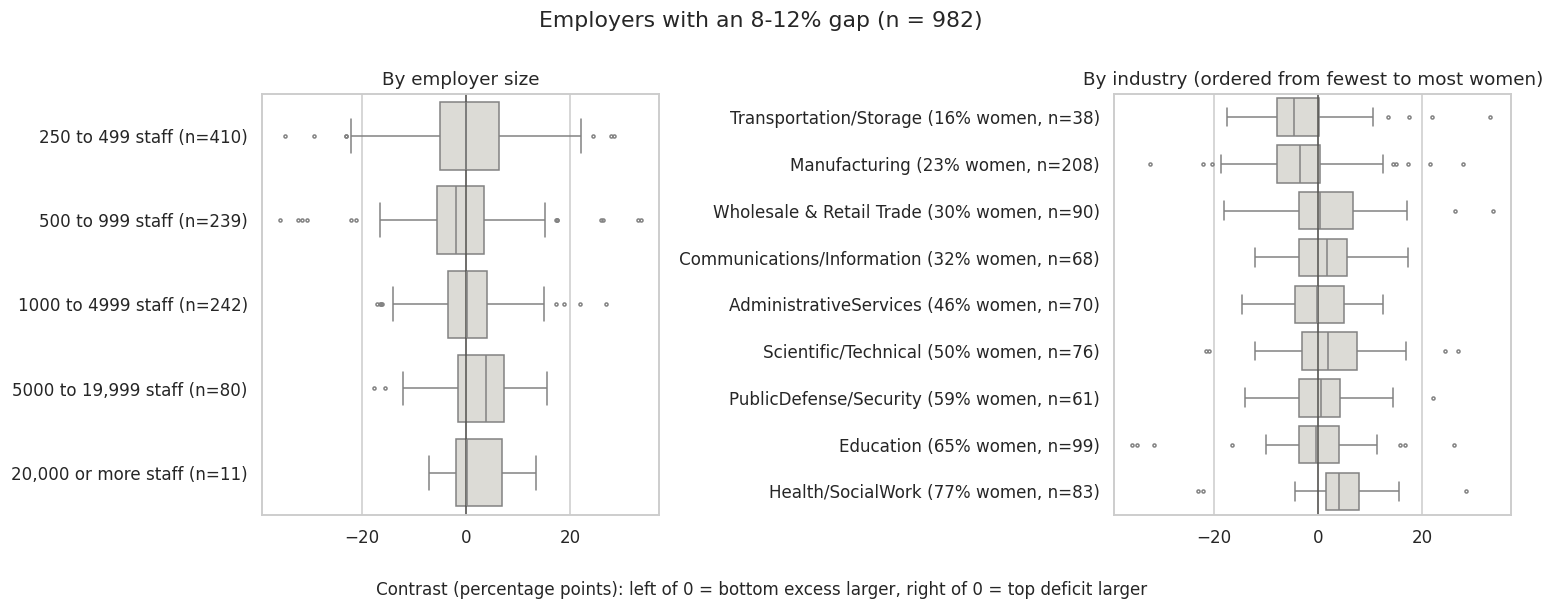

Across these industries, correlation between median women's share and median contrast: 0.72


In [11]:
# --- Levent: 4.6 third variables: employer size and industry ---
# AI-assisted (Claude Fable 5.2, November 2026)

# Industries with at least 30 employers in the band, ordered from fewest to most women.
# "Unknown" is left out because it is a missing label, not an industry.
by_industry = band[band["Industry"] != "Unknown"].groupby("Industry")
industry_table = pd.DataFrame({
    "Employers": by_industry["Contrast_pp"].size(),
    "Median women's share": by_industry["OverallFemaleShareApprox"].median(),
    "Median contrast": by_industry["Contrast_pp"].median(),
    "Top side larger, %": 100 * by_industry["TopLargerPoints"].mean(),
})
industry_table = industry_table[industry_table["Employers"] >= 30]
industry_table = industry_table.sort_values("Median women's share")
industry_order = list(industry_table.index)
display(industry_table.round(1))

by_size = band.groupby("EmployerSize")
size_table = pd.DataFrame({
    "Employers": by_size["Contrast_pp"].size(),
    "Median women's share": by_size["OverallFemaleShareApprox"].median(),
    "Median contrast": by_size["Contrast_pp"].median(),
    "Top side larger, %": 100 * by_size["TopLargerPoints"].mean(),
}).reindex(size_order)
display(size_table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharex=True)
sns.boxplot(data=band, y="EmployerSize", x="Contrast_pp", order=size_order, color="#dddcd5",
            fliersize=2, linewidth=1, ax=axes[0])
size_ticks = []
for name in size_order:
    size_ticks.append(f"{name} staff (n={size_table.loc[name, 'Employers']})")
axes[0].set_yticks(range(len(size_order)))
axes[0].set_yticklabels(size_ticks)
axes[0].set_ylabel("")
axes[0].set_title("By employer size")

industry_data = band[band["Industry"].isin(industry_order)]
sns.boxplot(data=industry_data, y="Industry", x="Contrast_pp", order=industry_order,
            color="#dddcd5", fliersize=2, linewidth=1, ax=axes[1])
industry_ticks = []
for name in industry_order:
    share = industry_table.loc[name, "Median women's share"]
    count = industry_table.loc[name, "Employers"]
    industry_ticks.append(f"{name} ({share:.0f}% women, n={count})")
axes[1].set_yticks(range(len(industry_order)))
axes[1].set_yticklabels(industry_ticks)
axes[1].set_ylabel("")
axes[1].set_title("By industry (ordered from fewest to most women)")
for ax in axes:
    ax.axvline(0, color=GRAY, linewidth=1)
    ax.set_xlabel("")
fig.supxlabel("Contrast (percentage points): left of 0 = bottom excess larger, "
              "right of 0 = top deficit larger", fontsize=11)
fig.suptitle(f"Employers with an 8-12% gap (n = {len(band)})", y=1.0)
plt.tight_layout()
save_figure("fig06_size_and_industry")
plt.show()

print("Across these industries, correlation between median women's share and median contrast:",
      round(industry_table["Median women's share"].corr(industry_table["Median contrast"]), 2))

**What the output shows**
- **Size: no clear pattern.** The median contrast is within 2 points of zero for four of the five size groups, and all the boxes overlap. The exception is 5,000–19,999 staff (+3.9, 80 employers). The largest group has only 11 employers, too few to read.
- **Industry: differences follow the gender mix.** Transport (16% women) and Manufacturing (23%) have median contrasts of −4.6 and −3.5, and the top side is the larger one for only 26% and 28% of their employers. Health and social work (77% women) has +4.1, and the top side is larger for 82%. Across the nine industries, the correlation between an industry's share of women and its median contrast is 0.72.
- **The other six industries straddle zero,** with medians between −0.4 and +2.0.
- **So industry adds little beyond gender mix.** With only nine industries, 0.72 is a rough guide, not a precise figure.

### 4.7 Is the contrast a real feature of an employer, or noise?

**Why.** Quartile shares are reported by employers and move a little every year. If the contrast were mostly noise, an employer's value this year would say little about its value last year. So we look up the same employers in the 2020–2021 filings and compare. The other year is used only as a check.

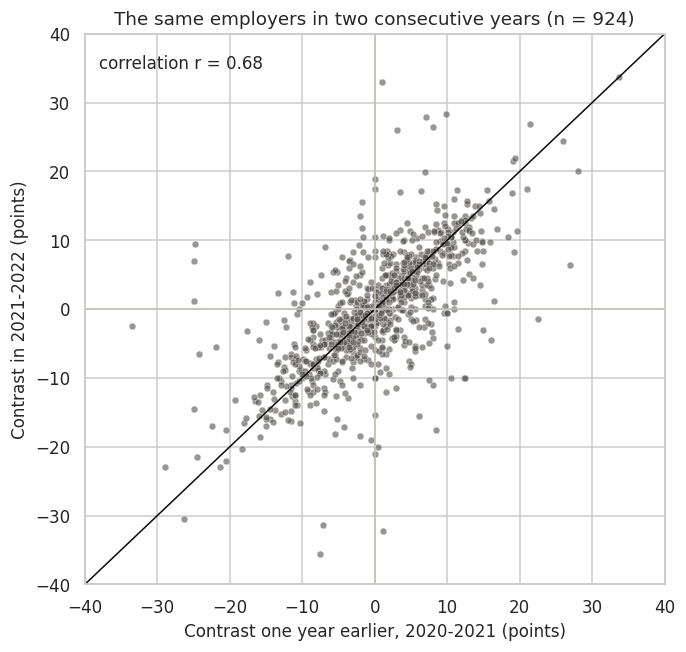

Band employers that also filed in 2020-2021: 924 of 982
Correlation of the contrast between the two years: 0.68
Same side larger in both years: 79.0 %
Same side in both years, among employers with a clear lean (more than 2 points): 84.0 % of 733
Typical change in an employer's contrast between the years: 2.4 points
Typical difference between employers (middle half): 10.2 points


In [12]:
# --- Levent: 4.7 is the contrast a real feature of an employer, or noise? ---
# AI-assisted (Claude Fable 5.2, November 2026)

# The same employers one reporting year earlier (2020-2021)
previous = all_filings[all_filings["ReportingPeriod"] == "2020-2021"].copy()
previous = previous[previous[female_cols].notna().all(axis=1)]
# a few employers filed twice that year; we cannot tell which filing is right, so drop them
previous = previous[~previous["EmployerId"].duplicated(keep=False)]
previous_overall = previous[female_cols].mean(axis=1).round(4)
previous["Contrast_prev"] = ((previous_overall - previous["FemaleTopQuartile"])
                             - (previous["FemaleLowerQuartile"] - previous_overall)).round(4)

# Keep the band employers that also filed the year before
both_years = band.merge(previous[["EmployerId", "Contrast_prev"]], on="EmployerId", how="inner")
r_years = both_years["Contrast_pp"].corr(both_years["Contrast_prev"])
same_side = (np.sign(both_years["Contrast_pp"]) == np.sign(both_years["Contrast_prev"])).mean()
clear = both_years[both_years["Contrast_pp"].abs() > 2]
same_side_clear = (np.sign(clear["Contrast_pp"]) == np.sign(clear["Contrast_prev"])).mean()
typical_change = (both_years["Contrast_pp"] - both_years["Contrast_prev"]).abs().median()

fig, ax = plt.subplots(figsize=(6.8, 6.5))
ax.scatter(both_years["Contrast_prev"], both_years["Contrast_pp"], s=20, alpha=0.6,
           color=GRAY, edgecolor="white", linewidth=0.4)
ax.plot([-40, 40], [-40, 40], color="#0b0b0b", linewidth=1)
ax.axhline(0, color=LIGHT_GRAY, linewidth=1)
ax.axvline(0, color=LIGHT_GRAY, linewidth=1)
ax.set_xlim(-40, 40)
ax.set_ylim(-40, 40)
ax.text(-38, 35, f"correlation r = {r_years:.2f}", fontsize=11)
ax.set_xlabel("Contrast one year earlier, 2020-2021 (points)")
ax.set_ylabel("Contrast in 2021-2022 (points)")
ax.set_title(f"The same employers in two consecutive years (n = {len(both_years)})")
save_figure("fig07_year_to_year")
plt.show()

print("Band employers that also filed in 2020-2021:", len(both_years), "of", len(band))
print("Correlation of the contrast between the two years:", round(r_years, 2))
print("Same side larger in both years:", round(100 * same_side, 1), "%")
print("Same side in both years, among employers with a clear lean (more than 2 points):",
      round(100 * same_side_clear, 1), "% of", len(clear))
print("Typical change in an employer's contrast between the years:",
      round(typical_change, 1), "points")
print("Typical difference between employers (middle half):",
      round(band["Contrast_pp"].quantile(0.75) - band["Contrast_pp"].quantile(0.25), 1), "points")

**What the output shows**
- **924 of the 982 employers also filed the year before.**
- **The contrast carries over.** The correlation between the two years is 0.68. Among employers with a clear lean this year (more than 2 points), 84% had the same side larger the year before.
- **Year-to-year movement is small next to the differences between employers.** An employer's contrast typically moves 2.4 points between years, while the middle half of employers spans about 10 points.
- **So the contrast is a lasting feature of an employer,** which is what a certification body needs before acting on it.
- **Limits.** The 58 employers with no usable filing the year before are not covered. An employer that repeats the same reporting mistake every year would also look stable.

### 4.8 Do our own choices drive the answer?

**Why.** We chose the 8–12% group, the 2-point tolerance, the 250+ rule, to keep the flagged filings, and the year. Each row below changes **one** of those choices and reruns the same summary.

In [13]:
# --- Levent: 4.8 do our own choices drive the answer? ---
# AI-assisted (Claude Fable 5.2, November 2026)

def build_sample(period, keep_small=False, drop_identical=False):
    # Repeats the sample rules of section 2 so we can change ONE rule at a time
    sample = all_filings[all_filings["ReportingPeriod"] == period].copy()
    if not keep_small:
        sample = sample[sample["EmployerSize"].isin(size_order)]
    usable = (sample[female_cols].notna().all(axis=1)
              & sample[female_cols].ge(0).all(axis=1)
              & sample[female_cols].le(100).all(axis=1))
    sample = sample[usable].copy()
    sample = sample[~sample["EmployerId"].duplicated(keep=False)]
    if drop_identical:
        sample = sample[sample[female_cols].nunique(axis=1) > 1]
    overall = sample[female_cols].mean(axis=1).round(4)
    sample["TopDeficit_pp"] = (overall - sample["FemaleTopQuartile"]).round(4)
    sample["BottomExcess_pp"] = (sample["FemaleLowerQuartile"] - overall).round(4)
    sample["Contrast_pp"] = (sample["TopDeficit_pp"] - sample["BottomExcess_pp"]).round(4)
    return sample

def summarize(sample, low, high, tolerance, description):
    group = sample[sample[gap_col].between(low, high)]
    group_labels = []
    for top, bottom in zip(group["TopDeficit_pp"], group["BottomExcess_pp"]):
        group_labels.append(pattern_label(top, bottom, tolerance))
    group_labels = pd.Series(group_labels)
    return {
        "Check": description,
        "Employers": len(group),
        "Median top deficit": group["TopDeficit_pp"].median(),
        "Median bottom excess": group["BottomExcess_pp"].median(),
        "Top deficit larger %": 100 * (group_labels == "Top deficit larger").mean(),
        "Bottom excess larger %": 100 * (group_labels == "Bottom excess larger").mean(),
        "Similar/unclear %": 100 * (group_labels == "Similar/unclear").mean(),
        "Neither positive %": 100 * (group_labels == "Neither positive").mean(),
    }

main_sample = build_sample(PERIOD)
print("The function rebuilds the main sample exactly:", len(main_sample) == len(df))

rows = []
rows.append(summarize(main_sample, 8, 12, 2, "MAIN: 2021-2022, gap 8-12%, tolerance 2"))
rows.append(summarize(main_sample, 9, 11, 2, "Narrower gap band: 9-11%"))
rows.append(summarize(main_sample, 5, 15, 2, "Wider gap band: 5-15%"))
rows.append(summarize(main_sample, 8, 12, 0, "Tolerance 0 points"))
rows.append(summarize(main_sample, 8, 12, 1, "Tolerance 1 point"))
rows.append(summarize(main_sample, 8, 12, 5, "Tolerance 5 points"))
with_small = build_sample(PERIOD, keep_small=True)
without_identical = build_sample(PERIOD, drop_identical=True)
rows.append(summarize(with_small, 8, 12, 2, "Including employers under 250 staff or no size given"))
rows.append(summarize(without_identical, 8, 12, 2, "Dropping identical-quartile filings"))
for other_period in ["2020-2021", "2019-2020", "2018-2019", "2017-2018"]:
    rows.append(summarize(build_sample(other_period), 8, 12, 2, "Other year: " + other_period))
robustness = pd.DataFrame(rows).set_index("Check")
display(robustness.round(1))

The function rebuilds the main sample exactly: True


,Employers,Median top deficit,Median bottom excess,Top deficit larger %,Bottom excess larger %,Similar/unclear %,Neither positive %
Check,,,,,,,
"MAIN: 2021-2022, gap 8-12%, tolerance 2",982,7.2,7.0,38.3,38.2,20.2,3.4
Narrower gap band: 9-11%,505,7.2,7.0,38.6,38.2,19.8,3.4
Wider gap band: 5-15%,2401,7.2,6.8,39.7,36.1,20.7,3.5
Tolerance 0 points,982,7.2,7.0,47.0,47.7,1.9,3.4
Tolerance 1 point,982,7.2,7.0,42.5,43.5,10.7,3.4
Tolerance 5 points,982,7.2,7.0,25.2,22.9,48.6,3.4
Including employers under 250 staff or no size given,1052,7.2,7.0,38.9,37.4,20.2,3.5
Dropping identical-quartile filings,981,7.2,7.1,38.3,38.2,20.2,3.3
Other year: 2020-2021,1000,8.0,6.9,41.6,34.3,21.3,2.8


**What the output shows**
- **Gap group width (9–11% or 5–15%):** the picture does not change. Top deficit larger 38–40%, bottom excess larger 36–38%.
- **Tolerance (0, 1 or 5 points):** the share that is "too close to call" moves from 2% to 49%, as it must, but the two sides stay within 2.5 points of each other at every setting.
- **Including smaller employers, or dropping the identical-quartile filings:** no visible change.
- **Compared with Josh's notebook:** the main row is identical (376 / 375 / 198 / 33). His rows for tolerances 0, 1 and 5 differ from ours by 1 to 3 employers, because of the rounding explained in section 3.
- **Other years:** both patterns are common in every year. In the four earlier years the top deficit was the larger side somewhat more often (41–44% against 34–35%); in 2021–2022 the two are level.

**What we can and cannot claim.** "Both patterns are common and neither dominates" holds in every row. "The split is exactly even" holds only for 2021–2022, so we do not claim it. We did not investigate why 2021–2022 is more level than earlier years.

## 5. Method 2: PCA

### 5.1 What PCA does, and the choices we made

**What PCA does, in plain words.** Every employer is described by four numbers (women's share in each quartile). PCA looks for the direction along which employers differ the most, then the next direction at right angles to it, and so on. Each direction is a **component**. A component is a recipe: a weight (called a **loading**) on each of the four inputs. An employer's **score** on a component says how far along that direction it sits.

**Why use it here.** In section 4 we *decided* to compare the top with the bottom, and built the contrast by hand. PCA is not told about that choice. It looks at all four quartiles at once and reports the main ways employers differ. If the top-versus-bottom contrast is really in the data, PCA should find something like it on its own. If PCA found something else entirely, our hand-built measure would be suspect.

**Choices, and why**
- **Inputs: the four female quartile shares only.** They are the variables the question is about, all numeric and all in the same unit.
- **No categorical columns.** PCA is defined for numbers. Turning industry or size into 0/1 columns would quietly assume every pair of industries is equally far apart. Those were handled with separate boxes in section 4.6 instead.
- **Not the pay gap itself.** It is the thing we hold fixed, not something to mix into the components.
- **Scaled or unscaled:** both are run and compared (5.2 and 5.6).

**What we did not use**
- **A PCA on all ten pay-gap measures** (Nick's notebook has one). It answers a broader question, and the bonus columns would shape the components.
- **t-SNE or UMAP.** They help when many dimensions have to be squeezed into two. Here each employer has only four numbers (three once its own average is removed), and distances in those plots cannot be interpreted.

### 5.2 First attempt: PCA on the quartile shares as they are

**Why.** The most direct thing to try: give PCA the four shares for the 982 employers with an 8–12% gap. It is run twice, unscaled (shares as reported) and scaled (each column rescaled to mean 0 and standard deviation 1), because PCA can change completely when inputs have different spreads.

In [14]:
# --- Levent: 5.2 first attempt: PCA on the four quartile shares as they are ---
# AI-assisted (Claude Fable 5.2, November 2026)
quartile_labels = ["Lowest-paid quartile", "Lower-middle quartile",
                   "Upper-middle quartile", "Highest-paid quartile"]

def run_pca(table):
    # Fits a PCA and returns three things:
    #   percent  = % of the total variation that each component carries
    #   loadings = the weight of each input in each component (the "recipe")
    #   scores   = where each employer sits along each component
    pca = PCA()
    score_values = pca.fit_transform(table)      # PCA subtracts each column's mean by itself
    names = []
    for i in range(table.shape[1]):
        names.append("PC" + str(i + 1))
    percent = pd.Series(pca.explained_variance_ratio_ * 100, index=names)
    loadings = pd.DataFrame(pca.components_.T, index=table.columns, columns=names)
    scores = pd.DataFrame(score_values, index=table.index, columns=names)
    return percent, loadings, scores

# Inputs: the four female quartile shares of the 8-12% band employers (all numeric, all in %)
raw = band[female_cols].copy()
raw.columns = quartile_labels

# Unscaled = shares as reported. Scaled = each column rescaled to mean 0, standard deviation 1.
raw_scaled = pd.DataFrame(StandardScaler().fit_transform(raw), index=raw.index, columns=raw.columns)

raw_percent, raw_loadings, raw_scores = run_pca(raw)
scaled_percent, scaled_loadings, scaled_scores = run_pca(raw_scaled)

print("Spread (standard deviation) of each input, in points:")
print(raw.std().round(1).to_string())
print()
display(pd.DataFrame({"Unscaled: % of variation": raw_percent,
                      "Scaled: % of variation": scaled_percent}).round(1))
print("Loadings, unscaled:")
display(raw_loadings.round(2))
print("Loadings, scaled:")
display(scaled_loadings.round(2))
print("Correlation between PC1 scores and women's overall share:",
      round(abs(raw_scores["PC1"].corr(band["OverallFemaleShareApprox"])), 3))

Spread (standard deviation) of each input, in points:
Lowest-paid quartile     22.5
Lower-middle quartile    24.3
Upper-middle quartile    24.5
Highest-paid quartile    21.6



,Unscaled: % of variation,Scaled: % of variation
PC1,93.0,92.9
PC2,3.2,3.2
PC3,2.1,2.3
PC4,1.6,1.5


Loadings, unscaled:


,PC1,PC2,PC3,PC4
Lowest-paid quartile,0.48,0.78,-0.40,0.09
Lower-middle quartile,0.52,-0.52,-0.49,-0.47
Upper-middle quartile,0.53,-0.32,0.18,0.76
Highest-paid quartile,0.46,0.15,0.76,-0.44


Loadings, scaled:


,PC1,PC2,PC3,PC4
Lowest-paid quartile,0.49,0.78,-0.37,0.02
Lower-middle quartile,0.50,-0.51,-0.43,-0.55
Upper-middle quartile,0.50,-0.34,-0.02,0.79
Highest-paid quartile,0.50,0.08,0.82,-0.26


Correlation between PC1 scores and women's overall share: 1.0


**What the output shows**
- **One component carries 93% of the variation,** scaled or not.
- **It is simply how many women the employer has.** Its four loadings are almost equal (0.46 to 0.53), meaning all four quartiles move up and down together, and its scores have a correlation of 1.00 with the overall share of women.
- **Scaling makes almost no difference here,** because the four inputs are in the same unit and have similar spreads (standard deviations of 21.6 to 24.5 points).
- **This attempt does not answer our question.** Going by the usual rule (keep the components that carry most of the variation) we would keep one component and learn only that employers differ in how female their workforce is. That is true, but it is not what we asked. The top-versus-bottom pattern is somewhere in the remaining 7%.

### 5.3 The fix: take out each employer's own average

**Why.** The first attempt was swamped by the overall share of women. The chart measures in section 3 avoid that by measuring each end *relative to the employer's own overall share*. We now give PCA the same treatment: from each of the four shares, subtract that employer's average. A value of +10 in a quartile then means "10 points more women here than in this employer overall".

**How many components to keep.** The scree plot (bars) and the running total (line) are the evidence. Because the four adjusted numbers always add up to zero, only three of them are free, so the fourth component is empty by construction.

**About signs.** The sign of a component is arbitrary: multiplying all its loadings and scores by −1 describes exactly the same direction. To make the output easy to read, the code flips PC1 if needed so that a high score means "top deficit larger", and PC2 so that a high score means "bigger drop in women's share from bottom to top".

,Raw shares: % of variation,Raw shares: running total,Own average removed: % of variation,Own average removed: running total
PC1,93.0,93.0,47.0,47.0
PC2,3.2,96.3,30.0,76.9
PC3,2.1,98.4,23.1,100.0
PC4,1.6,100.0,0.0,100.0


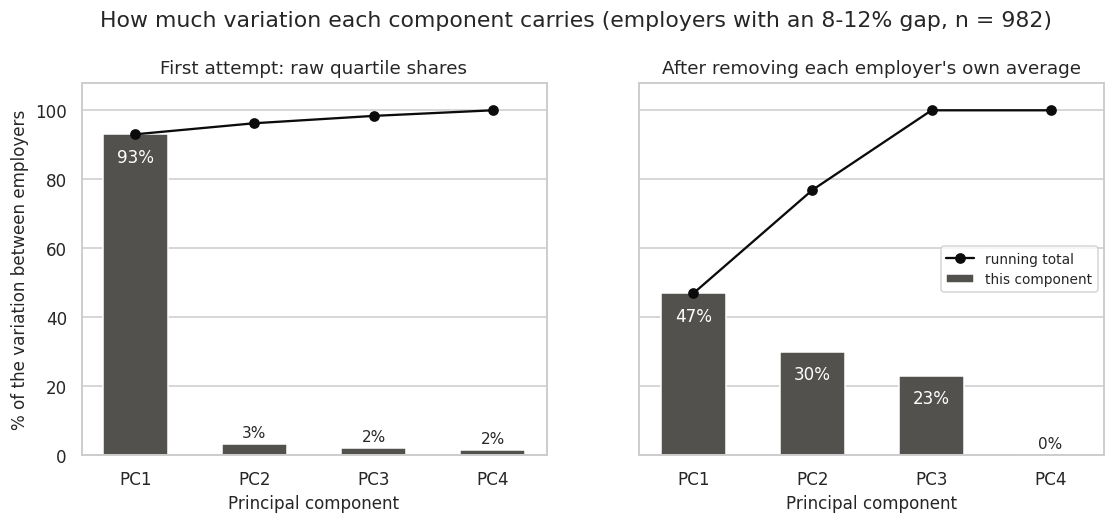

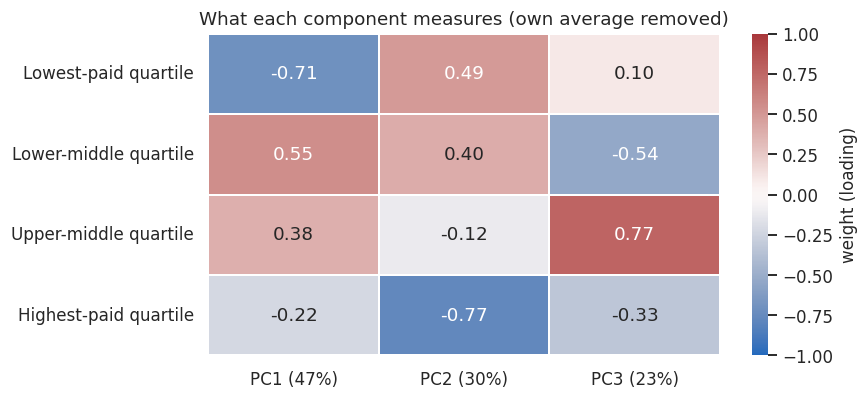

Correlation of each component's scores with the chart measures:


,with contrast,with top deficit,with bottom excess,with bottom minus top,with women's overall share
PC1,0.96,0.32,-0.87,-0.42,0.25
PC2,0.23,0.89,0.48,0.87,0.15
PC3,0.17,0.33,0.09,0.26,0.16


In [15]:
# --- Levent: 5.3 the fix: take out each employer's own average, then run PCA again ---
# AI-assisted (Claude Fable 5.2, November 2026)

# For every employer: share in each quartile MINUS that employer's overall share.
# +10 in a quartile now means "10 points more women here than in the employer as a whole".
shape = raw.sub(band["OverallFemaleShareApprox"], axis=0)

shape_percent, shape_loadings, shape_scores = run_pca(shape)

def point_same_way(scores, loadings, component, reference):
    # The sign of a principal component is arbitrary: flipping it changes nothing real.
    # To make it easy to read, flip it if needed so that a HIGH score goes with
    # a HIGH value of the reference measure.
    if scores[component].corr(reference) < 0:
        scores[component] = -scores[component]
        loadings[component] = -loadings[component]

bottom_minus_top = band["FemaleLowerQuartile"] - band["FemaleTopQuartile"]
# high PC1 = top deficit larger
point_same_way(shape_scores, shape_loadings, "PC1", band["Contrast_pp"])
# high PC2 = bigger drop in women's share from bottom to top
point_same_way(shape_scores, shape_loadings, "PC2", bottom_minus_top)

variance_table = pd.DataFrame({
    "Raw shares: % of variation": raw_percent,
    "Raw shares: running total": raw_percent.cumsum(),
    "Own average removed: % of variation": shape_percent,
    "Own average removed: running total": shape_percent.cumsum(),
})
display(variance_table.round(1))

# Scree plots: bars = each component, line = running total
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, percent, title in [(axes[0], raw_percent, "First attempt: raw quartile shares"),
                           (axes[1], shape_percent, "After removing each employer's own average")]:
    ax.bar(percent.index, percent.values, color=GRAY, width=0.55, label="this component")
    ax.plot(percent.index, percent.cumsum().values, color="#0b0b0b", marker="o",
            linewidth=1.5, label="running total")
    for i, value in enumerate(percent.values):
        if value > 15:      # tall bar: write the number inside it
            ax.text(i, value - 8, f"{value:.0f}%", ha="center", fontsize=11, color="white")
        else:               # short bar: write the number above it
            ax.text(i, value + 2, f"{value:.0f}%", ha="center", fontsize=10)
    ax.set_ylim(0, 108)
    ax.set_title(title)
    ax.set_xlabel("Principal component")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% of the variation between employers")
axes[1].legend(loc="center right", fontsize=9)
fig.suptitle("How much variation each component carries "
             f"(employers with an 8-12% gap, n = {len(band)})", y=1.03)
save_figure("fig08_scree")
plt.show()

# What each component is made of
shown = shape_loadings[["PC1", "PC2", "PC3"]].copy()
shown.columns = [f"PC1 ({shape_percent['PC1']:.0f}%)", f"PC2 ({shape_percent['PC2']:.0f}%)",
                 f"PC3 ({shape_percent['PC3']:.0f}%)"]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.heatmap(shown, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            linewidths=1, cbar_kws={"label": "weight (loading)"}, ax=ax)
ax.set_title("What each component measures (own average removed)")
ax.set_ylabel("")
save_figure("fig09_loadings")
plt.show()

print("Correlation of each component's scores with the chart measures:")
# corrwith gives the correlation of each column (PC1, PC2, PC3) with one measure
three = shape_scores[["PC1", "PC2", "PC3"]]
check = pd.DataFrame({
    "with contrast": three.corrwith(band["Contrast_pp"]),
    "with top deficit": three.corrwith(band["TopDeficit_pp"]),
    "with bottom excess": three.corrwith(band["BottomExcess_pp"]),
    "with bottom minus top": three.corrwith(bottom_minus_top),
    "with women's overall share": three.corrwith(band["OverallFemaleShareApprox"]),
})
display(check.round(2))

**What the output shows**
- **The variation is now spread over three components: 47%, 30% and 23%.** There is no sharp drop after the first one, so no single pattern dominates. We read all three, and say plainly that the structure is moderate.
- **PC1 (47%) is the top-versus-bottom contrast.** It puts a negative weight on the lowest-paid quartile (−0.71), positive weights on the two middle quartiles (+0.55 and +0.38) and a small negative weight on the highest-paid quartile (−0.22). A high score therefore means fewer women at the ends than in the middle, which is what a positive contrast means. Its correlation with the contrast from the charts is **0.96**.
- **PC1 leans more on the bottom than on the top.** Its correlation is −0.87 with bottom excess but only +0.32 with top deficit. So it is close to our contrast but not identical: PCA gives the lowest-paid quartile more weight, in line with bottom excess varying more between employers than top deficit does (standard deviation 7.0 against 6.0 points).
- **PC2 (30%) is the size of the drop from bottom to top.** High scores mean more women in the lower half and fewer in the highest-paid quartile (correlation 0.87 with the bottom share minus the top share). Even among employers with a similar pay gap this still varies, because the median pay gap and the headcount in each quartile are not the same thing.
- **PC3 (23%) concerns the two middle quartiles** (lower-middle against upper-middle). It is not about the ends of the pay ladder, so it does not bear on our question.

### 5.4 Bring it back to the variables

**Why.** A pattern that only exists after a transformation is fragile. Two checks: does the PC1 score line up with the contrast we built by hand, and can we see PC1 in a plot of the original two measures?

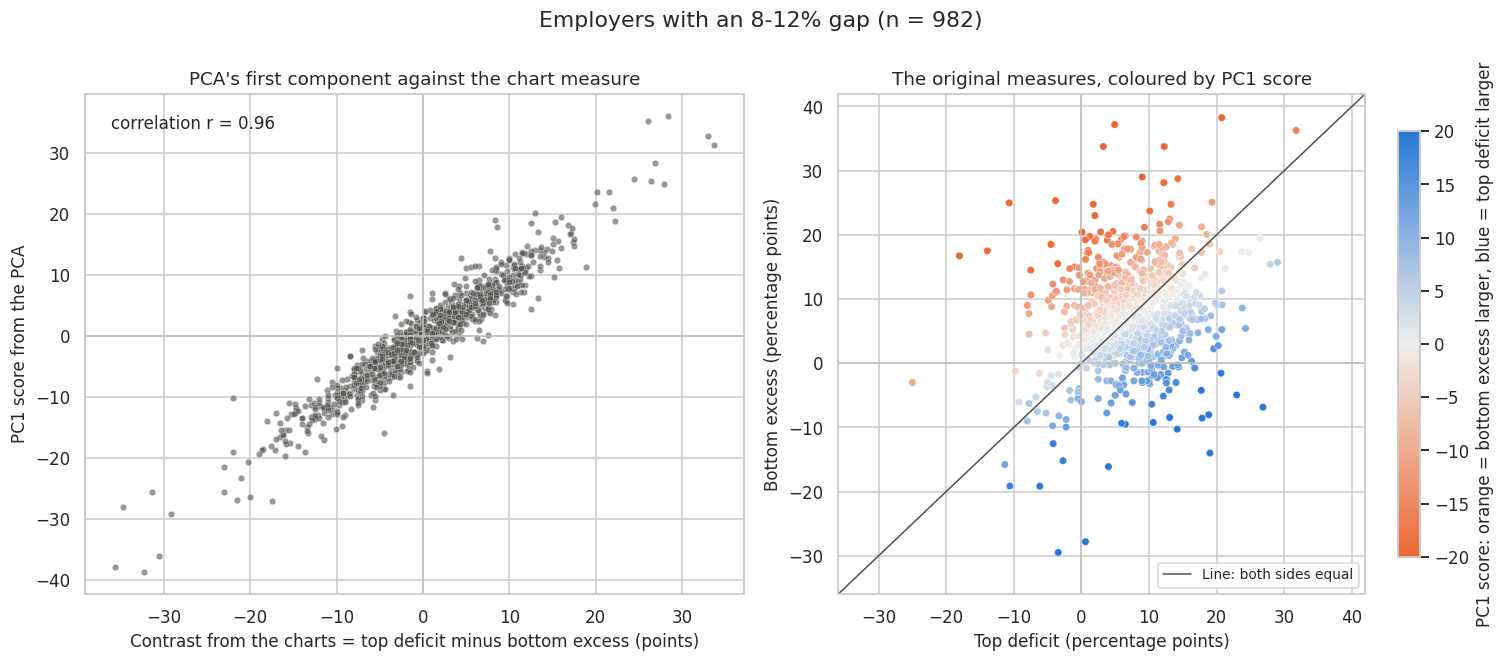

PC1 scores of the two example employers from section 4.1:
   Goodwood Road Racing Company Limited -> 7.7
   Warner Bros. Studios Leavesden Limited -> -11.1


In [16]:
# --- Levent: 5.4 bring it back to the variables ---
# AI-assisted (Claude Fable 5.2, November 2026)
from matplotlib.colors import LinearSegmentedColormap
lean_colors = LinearSegmentedColormap.from_list("lean", [ORANGE, "#f0efec", BLUE])

r_pca = shape_scores["PC1"].corr(band["Contrast_pp"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: the PCA score against the measure we built by hand
axes[0].scatter(band["Contrast_pp"], shape_scores["PC1"], s=18, alpha=0.6, color=GRAY,
                edgecolor="white", linewidth=0.3)
axes[0].axhline(0, color=LIGHT_GRAY, linewidth=1)
axes[0].axvline(0, color=LIGHT_GRAY, linewidth=1)
axes[0].text(0.04, 0.93, f"correlation r = {r_pca:.2f}", transform=axes[0].transAxes, fontsize=11)
axes[0].set_xlabel("Contrast from the charts = top deficit minus bottom excess (points)")
axes[0].set_ylabel("PC1 score from the PCA")
axes[0].set_title("PCA's first component against the chart measure")

# Right: the original two measures, each employer coloured by its PC1 score
limit = 20
dots = axes[1].scatter(band["TopDeficit_pp"], band["BottomExcess_pp"],
                       c=shape_scores["PC1"], cmap=lean_colors, vmin=-limit, vmax=limit,
                       s=24, edgecolor="white", linewidth=0.3)
axes[1].plot([-36, 42], [-36, 42], color=GRAY, linewidth=1, label="Line: both sides equal")
axes[1].legend(loc="lower right", fontsize=9)
axes[1].axhline(0, color=LIGHT_GRAY, linewidth=1)
axes[1].axvline(0, color=LIGHT_GRAY, linewidth=1)
axes[1].set_xlim(-36, 42)
axes[1].set_ylim(-36, 42)
axes[1].set_xlabel("Top deficit (percentage points)")
axes[1].set_ylabel("Bottom excess (percentage points)")
axes[1].set_title("The original measures, coloured by PC1 score")
colorbar = fig.colorbar(dots, ax=axes[1], shrink=0.85)
colorbar.set_label("PC1 score: orange = bottom excess larger, blue = top deficit larger")
fig.suptitle(f"Employers with an 8-12% gap (n = {len(band)})", y=1.0)
plt.tight_layout()
save_figure("fig10_pca_back_to_variables")
plt.show()

print("PC1 scores of the two example employers from section 4.1:")
for example in [example_top, example_bottom]:
    # example.name is the row label of that employer, which is how we find its score
    score = shape_scores.loc[example.name, "PC1"]
    print("  ", example["EmployerName"].title(), "->", round(score, 1))

**What the output shows**
- **Left: PC1 scores line up with the contrast,** correlation 0.96. PCA arrived at nearly the same measure on its own.
- **Right: the same chart as section 4.2, coloured by PC1 score.** Colour changes from orange to blue as you cross the diagonal, so PC1 is the direction that separates "bottom excess larger" from "top deficit larger".
- **The two example employers from 4.1 land at opposite ends:** Goodwood Road Racing scores +7.7 and Warner Bros. Studios Leavesden −11.1. Warner Bros. sits further out because PC1 puts most of its weight on the lowest-paid quartile.
- **The match is 0.96, not 1.00,** because PC1 weighs the lowest-paid quartile more heavily than the highest-paid one.

### 5.5 The same PCA on employers of every gap size

**Why.** Section 4.4 showed with charts that the balance between top and bottom does not depend on the size of the gap. Here PCA is run on all 9,494 employers (own average removed, as in 5.3) to see whether it tells the same story once all four quartiles are in play.

,% of variation,running total
PC1,52.9,52.9
PC2,29.2,82.1
PC3,17.9,100.0
PC4,0.0,100.0


,PC1,PC2,PC3
Lowest-paid quartile,0.74,-0.44,0.13
Lower-middle quartile,0.16,0.71,-0.47
Upper-middle quartile,-0.33,0.24,0.76
Highest-paid quartile,-0.57,-0.50,-0.42


Rank correlations (Spearman) of each component's scores:


,with the median pay gap,with contrast,with bottom minus top
PC1,0.73,-0.19,0.97
PC2,0.14,0.94,0.08
PC3,-0.06,0.26,0.23


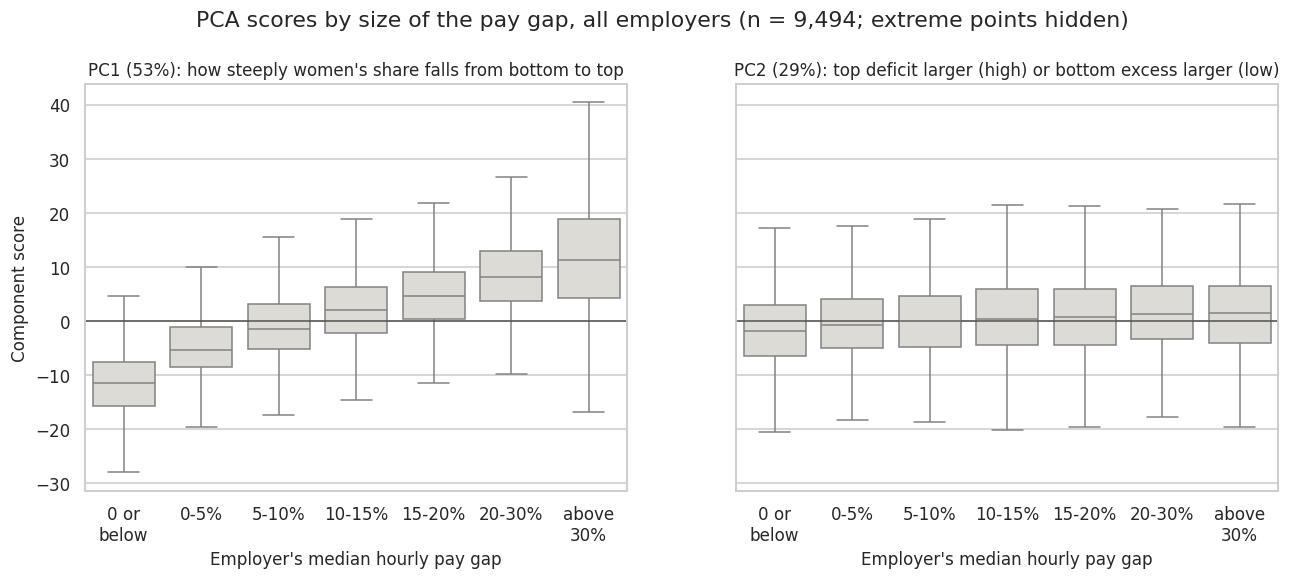

In [17]:
# --- Levent: 5.5 the same PCA on employers of EVERY gap size ---
# AI-assisted (Claude Fable 5.2, November 2026)
shape_all = df[female_cols].sub(df["OverallFemaleShareApprox"], axis=0)
shape_all.columns = quartile_labels

all_percent, all_loadings, all_scores = run_pca(shape_all)
bottom_minus_top_all = df["FemaleLowerQuartile"] - df["FemaleTopQuartile"]
# high PC1 = bigger drop in women's share from bottom to top
point_same_way(all_scores, all_loadings, "PC1", bottom_minus_top_all)
# high PC2 = top deficit larger
point_same_way(all_scores, all_loadings, "PC2", df["Contrast_pp"])

display(pd.DataFrame({"% of variation": all_percent,
                      "running total": all_percent.cumsum()}).round(1))
display(all_loadings[["PC1", "PC2", "PC3"]].round(2))

three_all = all_scores[["PC1", "PC2", "PC3"]]
links = pd.DataFrame({
    "with the median pay gap": three_all.corrwith(df[gap_col], method="spearman"),
    "with contrast": three_all.corrwith(df["Contrast_pp"], method="spearman"),
    "with bottom minus top": three_all.corrwith(bottom_minus_top_all, method="spearman"),
})
print("Rank correlations (Spearman) of each component's scores:")
display(links.round(2))

score_table = pd.DataFrame({"GapBand": df["GapBand"],
                            "PC1": all_scores["PC1"], "PC2": all_scores["PC2"]})
title_1 = f"PC1 ({all_percent['PC1']:.0f}%): how steeply women's share falls from bottom to top"
title_2 = (f"PC2 ({all_percent['PC2']:.0f}%): "
           "top deficit larger (high) or bottom excess larger (low)")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, component, title in [(axes[0], "PC1", title_1), (axes[1], "PC2", title_2)]:
    sns.boxplot(data=score_table, x="GapBand", y=component, order=gap_names, color="#dddcd5",
                showfliers=False, linewidth=1, ax=ax)
    ax.axhline(0, color=GRAY, linewidth=1)
    ax.set_xticks(range(len(gap_names)))
    ax.set_xticklabels(["0 or\nbelow", "0-5%", "5-10%", "10-15%", "15-20%", "20-30%", "above\n30%"])
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Employer's median hourly pay gap")
    ax.set_ylabel("")
axes[0].set_ylabel("Component score")
fig.suptitle("PCA scores by size of the pay gap, all employers "
             f"(n = {len(df):,}; extreme points hidden)", y=1.02)
save_figure("fig11_pca_all_employers")
plt.show()

**What the output shows**
- **PC1 (53%) is how steeply women's share falls from the bottom to the top of the pay ladder.** It has positive weights on the two lower quartiles and negative weights on the two upper ones. Its scores climb steadily with the pay gap (left chart; rank correlation 0.73).
- **PC2 (29%) is the top-versus-bottom contrast again** (rank correlation 0.94 with the chart contrast). Its boxes are nearly level across the gap groups, with a slight upward drift (right chart; rank correlation with the gap only 0.14).
- **So a pay gap has two separate sides:** how big the imbalance is, which the headline gap tracks, and where it sits, which the headline gap does not track.
- **Why the order differs from 5.3.** Across all employers, steepness is the biggest difference. Once the gap is held roughly fixed, steepness varies less, and the top-versus-bottom contrast becomes the largest.
- **Why rank correlation.** A handful of employers report extreme gaps, and ranks are not thrown off by them.

### 5.6 Scaled or unscaled?

**Why.** The directives ask us to say whether we scaled, and why. After removing each employer's average, the four inputs no longer have quite the same spread, so the choice could matter more than it did in 5.2.

In [18]:
# --- Levent: 5.6 scaled or unscaled? ---
# AI-assisted (Claude Fable 5.2, November 2026)
shape_scaled = pd.DataFrame(StandardScaler().fit_transform(shape),
                            index=shape.index, columns=shape.columns)
scaled2_percent, scaled2_loadings, scaled2_scores = run_pca(shape_scaled)
point_same_way(scaled2_scores, scaled2_loadings, "PC1", band["Contrast_pp"])

print("Spread (standard deviation) of each input, own average removed, in points:")
print(shape.std().round(1).to_string())
display(pd.DataFrame({"Unscaled: % of variation": shape_percent,
                      "Scaled: % of variation": scaled2_percent}).round(1))
display(pd.DataFrame({"Unscaled PC1 loadings": shape_loadings["PC1"],
                      "Scaled PC1 loadings": scaled2_loadings["PC1"]}).round(2))
r_unscaled = shape_scores["PC1"].corr(band["Contrast_pp"])
r_scaled = scaled2_scores["PC1"].corr(band["Contrast_pp"])
print("Correlation of PC1 with the contrast -> unscaled:", round(r_unscaled, 3),
      "| scaled:", round(r_scaled, 3))

Spread (standard deviation) of each input, own average removed, in points:
Lowest-paid quartile     7.0
Lower-middle quartile    6.3
Upper-middle quartile    5.7
Highest-paid quartile    6.0


,Unscaled: % of variation,Scaled: % of variation
PC1,47.0,44.6
PC2,30.0,30.0
PC3,23.1,25.4
PC4,0.0,0.0


,Unscaled PC1 loadings,Scaled PC1 loadings
Lowest-paid quartile,-0.71,-0.56
Lower-middle quartile,0.55,0.54
Upper-middle quartile,0.38,0.49
Highest-paid quartile,-0.22,-0.39


Correlation of PC1 with the contrast -> unscaled: 0.959 | scaled: 0.999


**What the output shows**
- **The spreads are close but not equal** (standard deviations of 5.7 to 7.0 points).
- **Both versions tell the same story.** Unscaled gives 47% / 30% / 23%, scaled gives 45% / 30% / 25%. PC1 is the contrast in both (correlation 0.959 unscaled, 0.999 scaled).
- **We keep the unscaled version.** All four inputs are percentage points of the same thing, so a point in one quartile should count the same as a point in another. Scaling would stretch the quartiles that vary less, which has no meaning here. Scaling is the right call when inputs are in different units, which is not our case.
- **We do not switch to the scaled version because it matches our measure more closely.** That would be picking the method by its answer.

## 6. Do the two methods agree?

| Finding | Charts (section 4) | PCA (section 5) |
|---|---|---|
| Employers with a similar gap do not look alike | The contrast spans −10 to +10 for eight in ten employers (4.3) | With the overall share removed, the largest component is the top-versus-bottom contrast, 47% (5.3) |
| Both methods see the same thing | Contrast built by hand | PC1, found without being told; correlation 0.96 (5.4) |
| One continuous range, not two camps | One hump in the histogram (4.3) | PC1 scores form one cloud with no break (5.4, left chart) |
| Where the imbalance sits does not depend on the size of the gap | The balance is the same in every gap group; rank correlation −0.05 (4.4) | Steepness tracks the gap (0.73); the contrast component does not (0.14) (5.5) |
| The pattern is moderate, not overwhelming | Group medians differ by a few points, while individual employers differ by ten or more (4.5, 4.6) | 47% / 30% / 23%: no single dominant component (5.3) |

**What PCA adds that the charts did not show.** Among same-gap employers, the size of the drop from bottom to top still varies (PC2, 30%). The median pay gap does not fully pin down the headcount pattern.

**What the charts add that PCA did not show.** The link with gender mix (4.5), the stability over time (4.7), and real employers to point to (4.1).

## 7. The answer, and what the client would do differently

**Answer.** Employers with a similar pay gap do **not** look alike.
1. **Most have both a top deficit and a bottom excess** (83%), and for the typical employer the two are about equal (medians of 7.25 and 7.05 points).
2. **But the balance varies widely from employer to employer.** The top side is clearly larger for 38%, the bottom side for 38%, and 20% are too close to call.
3. **They are not two separate types.** Employers form one continuous range from bottom-heavy to top-heavy.
4. **The balance is a lasting feature of an employer** (correlation 0.68 with the year before).
5. **It is unrelated to the size of the gap, and related to the gender mix.** Mostly-male employers lean toward bottom excess, mostly-female employers toward top deficit.
6. **PCA agrees.** With the overall share removed, the main way same-gap employers differ is this same top-versus-bottom contrast.

**Against the three results that would have surprised us**
- **A similar gap always going with a similar pattern:** did not happen.
- **Two separate camps:** did not happen.
- **The bottom mattering as much as the top:** happened. The glass ceiling is half of the picture.

**What the certification body would do differently**
- **Stop treating the headline gap as the whole story.** Two employers with a 10% gap can need opposite follow-ups.
- **Read the quartile figures it already receives.** Comparing top deficit with bottom excess takes one subtraction per employer and no new data.
- **Match the follow-up to the pattern.** Top deficit clearly larger: ask about promotion and senior hiring. Bottom excess clearly larger: ask who is hired into the lowest-paid roles and how they move up. Close to equal: ask about both.
- **Expect the pattern to follow the gender mix.** A mostly-male employer is more likely to show the bottom-side pattern, a mostly-female one the top-side pattern.

**How sure are we?**
- **Solid:** employers with a similar gap differ, along one continuous range. This holds for other gap widths, tolerances, sample rules and years, it is stable over time, and both methods find it.
- **Reasonably sure:** the link with gender mix. Its direction holds on two yardsticks; its size depends on the yardstick.
- **Not claimed:** an exactly even split (true only for 2021–2022), and anything about causes.

## 8. Assumptions and limitations

**About the data**
- **Self-reported.** Employers compute and enter their own figures. The 18 filings with identical quartiles and the 3 with extreme gaps show that errors exist. Dropping the identical ones changed nothing (4.8), but smaller errors cannot be seen.
- **Only employers with 250 or more staff that filed.** Nothing here speaks for smaller employers, or for those that did not report.
- **One year, 2021–2022.** Earlier years tilt slightly more toward top deficit (4.8). The pay snapshot for 2021–2022 is April 2021, when the furlough scheme was running, and staff on reduced furlough pay were left out of employers' figures. We did not adjust for this.
- **Quartile shares are headcounts.** They say how many women are in each pay quartile, not what anyone is paid inside it, and not whether people doing the same job are paid the same.

**About the measures**
- **Overall share is approximated** by the average of the four quartiles (exact when the quartiles are the same size).
- **Top deficit and bottom excess are tied together by arithmetic.** They share a reference point, and the four quartile differences add up to zero. The contrast is a summary of all four quartiles, not two independent facts.
- **Percentage points are capped at 0 and 100,** which pushes employers with very few or very many women toward one side (4.5). The odds yardstick reduces this but needs its own assumption (shares kept between 0.5 and 99.5).
- **"Similar gap" is a judgement call.** 8–12% is our choice; 9–11% and 5–15% give the same picture.
- **The 2-point tolerance is a judgement call.** The labelled counts move with it. The histogram does not depend on it.
- **The median gap and the quartile headcounts are different things.** Employers with the same median gap can have different drops from bottom to top (5.3, PC2).

**About the methods**
- **Charts can mislead.** Medians alone and labelled counts alone each suggested a wrong reading (4.3).
- **PCA here has only four inputs,** so it is a modest tool. Its main job was to confirm a direction, not to uncover hidden structure.
- **PCA finds straight-line patterns only.** Its components are descriptions, not causes, and their signs are arbitrary.
- **The structure is moderate** (47% / 30% / 23%). The contrast is the largest way same-gap employers differ in shape, not the only one.
- **Everything is descriptive.** Gender mix and industry go along with the contrast. Nothing here shows they cause it.

**With more time or better data**
- **Follow the same employers over all five years** to see whether the contrast shifts as their gap closes.
- **Use pay within each quartile,** if it were available, to separate where women sit from what they are paid there.

## 9. What we tried that did not work, and what we changed

- **PCA on the raw shares (5.2).** It answered a different question: 93% of the variation was just how many women an employer has. Fix: remove each employer's own average (5.3).
- **Sorting employers into a "top" type and a "bottom" type.** The counts looked like two camps of 38% each, but the histogram showed one continuous range, and the counts moved with the tolerance (4.3, 4.8). We now describe a range and use the labels only as a summary.
- **Reading industry differences at face value.** They turned out to follow the share of women in each industry (4.6), so gender mix is reported as the third variable that matters.
- **Relying on percentage points alone for the gender-mix result.** Because of the 0 to 100 cap we added the odds yardstick. The pattern shrank but stayed (4.5).
- **Assuming the even split was general.** Other years show a modest tilt toward top deficit, so the claim was narrowed (4.8).
- **Counting "which side is larger" on unrounded numbers.** Tiny computer rounding errors turned 3 exact ties into "top side larger". Fix: round the measures to 4 decimal places (section 3).

## 10. Running this notebook again

- **Nothing to upload.** The data is read from the team repository.
- **To check it from scratch:** Runtime → Restart session and run all. The 8–12% group should have 982 employers, split 376 / 375 / 198 / 33.
- **Charts are also saved as PNG files** (`fig00_pipeline.png` to `fig11_pca_all_employers.png`) in the Files panel, for the report.